In [ ]:
import pandas as pd

df_khartoum = pd.read_csv(
    "Khartoum.txt",
    sep=";",
    skiprows=37,
    names=["date", "time", "original", "calculated", "flag"],
    na_values=[-999.000, "-999.000"],
    encoding="latin-1"
)

print(df_khartoum.head(10))

         date   time     original   calculated   flag
0      # DATA    NaN          NaN          NaN    NaN
1  YYYY-MM-DD  hh:mm     Original   Calculated   Flag
2  1900-01-01  --:--      254.630     -999.000      0
3  1900-02-01  --:--      138.889     -999.000      0
4  1900-03-01  --:--       92.593     -999.000      0
5  1900-04-01  --:--       92.593     -999.000      0
6  1900-05-01  --:--      150.463     -999.000      0
7  1900-06-01  --:--      347.222     -999.000      0
8  1900-07-01  --:--     1689.815     -999.000      0
9  1900-08-01  --:--     7164.352     -999.000      0


In [ ]:
import pandas as pd

df_khartoum = pd.read_csv(
    "Khartoum.txt",
    sep=";",
    skiprows=39,
    names=["date", "time", "original", "calculated", "flag"],
    na_values=[-999.000, "-999.000"],
    encoding="latin-1"
)

print(df_khartoum.head(10))

         date   time  original  calculated  flag
0  1900-01-01  --:--   254.630         NaN     0
1  1900-02-01  --:--   138.889         NaN     0
2  1900-03-01  --:--    92.593         NaN     0
3  1900-04-01  --:--    92.593         NaN     0
4  1900-05-01  --:--   150.463         NaN     0
5  1900-06-01  --:--   347.222         NaN     0
6  1900-07-01  --:--  1689.815         NaN     0
7  1900-08-01  --:--  7164.352         NaN     0
8  1900-09-01  --:--  5590.278         NaN     0
9  1900-10-01  --:--  2881.944         NaN     0


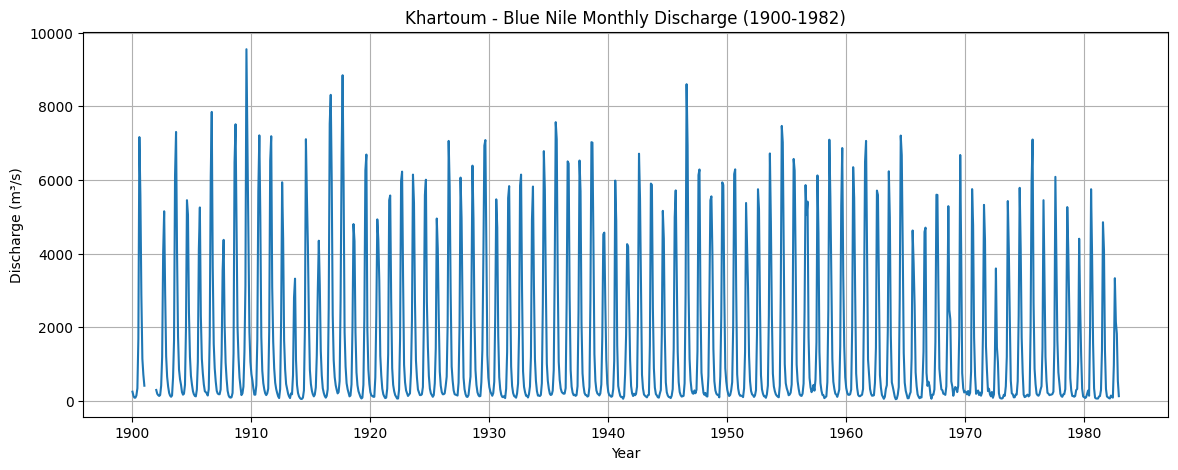

In [ ]:
import matplotlib.pyplot as plt

# Convert date column to actual datetime format
df_khartoum["date"] = pd.to_datetime(df_khartoum["date"])

# Plot
plt.figure(figsize=(14, 5))
plt.plot(df_khartoum["date"], df_khartoum["original"])
plt.title("Khartoum - Blue Nile Monthly Discharge (1900-1982)")
plt.xlabel("Year")
plt.ylabel("Discharge (m³/s)")
plt.grid(True)
plt.show()

In [ ]:
!pip install pywavelets

In [ ]:
# Fill missing values using interpolation (estimates gaps based on surrounding points)
df_khartoum["discharge_filled"] = df_khartoum["original"].interpolate(method="linear")

# Check how many values were originally missing
print("Missing values before filling:", df_khartoum["original"].isna().sum())
print("Missing values after filling:", df_khartoum["discharge_filled"].isna().sum())

Missing values before filling: 11
Missing values after filling: 0


In [ ]:
import pywt
import numpy as np

# Get the filled discharge data as a plain array
signal = df_khartoum["discharge_filled"].values

# Decompose using a Daubechies-4 wavelet, 4 levels deep
coeffs = pywt.wavedec(signal, 'db4', level=4)

# coeffs[0] = approximation (long-term trend)
# coeffs[1:] = detail coefficients (seasonal + noise, different frequency levels)

print("Number of components:", len(coeffs))
for i, c in enumerate(coeffs):
    print(f"Component {i}: length {len(c)}")

Number of components: 5
Component 0: length 68
Component 1: length 68
Component 2: length 130
Component 3: length 254
Component 4: length 501


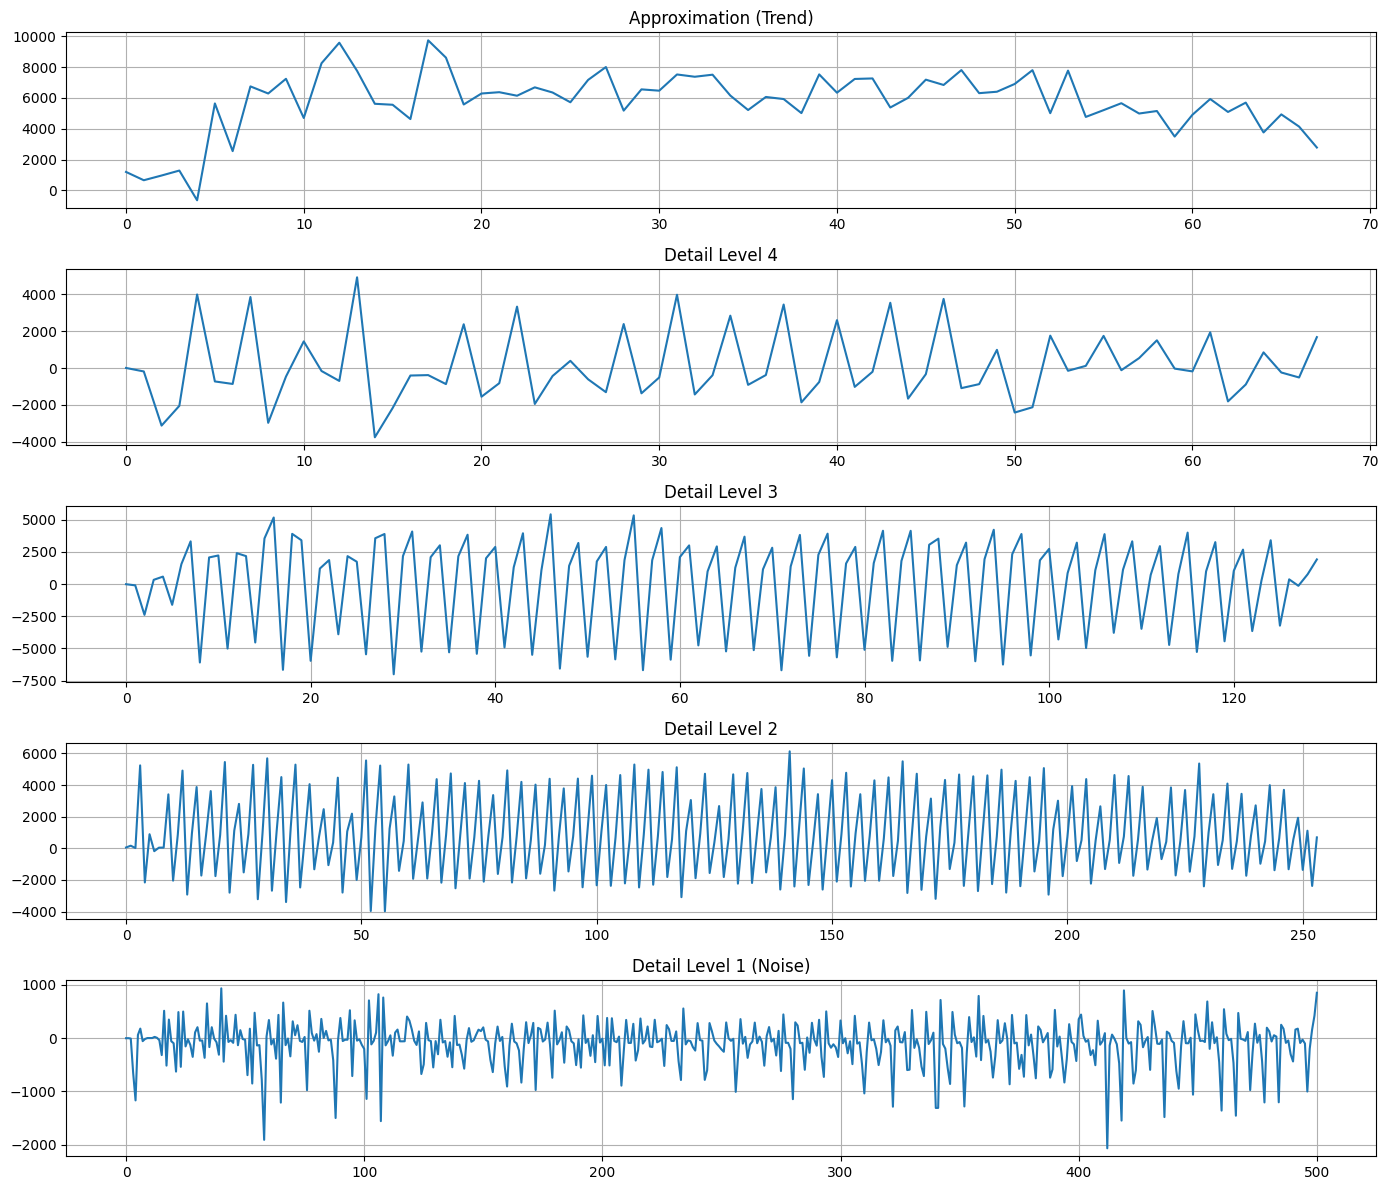

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(coeffs), 1, figsize=(14, 12))

labels = ["Approximation (Trend)", "Detail Level 4", "Detail Level 3", "Detail Level 2", "Detail Level 1 (Noise)"]

for i, (c, label) in enumerate(zip(coeffs, labels)):
    axes[i].plot(c)
    axes[i].set_title(label)
    axes[i].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Threshold the noisy detail coefficients (soft thresholding)
threshold = np.std(coeffs[-1]) * 2  # simple universal threshold based on noise level

denoised_coeffs = coeffs.copy()
denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')  # only denoise the noisiest level

# Reconstruct the denoised signal
denoised_signal = pywt.waverec(denoised_coeffs, 'db4')

# Match length (wavelet reconstruction can be 1 sample off)
denoised_signal = denoised_signal[:len(signal)]

print("Original signal length:", len(signal))
print("Denoised signal length:", len(denoised_signal))

Original signal length: 996
Denoised signal length: 996


In [ ]:
import numpy as np

def create_lagged_features(data, n_lags=12):
    X, y = [], []
    for i in range(n_lags, len(data)):
        X.append(data[i-n_lags:i])
        y.append(data[i])
    return np.array(X), np.array(y)

# Create features from raw (filled) signal
X_raw, y_raw = create_lagged_features(signal, n_lags=12)

# Create features from denoised signal
X_denoised, y_denoised = create_lagged_features(denoised_signal, n_lags=12)

print("Raw X shape:", X_raw.shape)
print("Denoised X shape:", X_denoised.shape)

Raw X shape: (984, 12)
Denoised X shape: (984, 12)


In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Split: use first 80% for training, last 20% for testing (respects time order - no shuffling)
split_idx = int(len(X_raw) * 0.8)

X_raw_train, X_raw_test = X_raw[:split_idx], X_raw[split_idx:]
y_raw_train, y_raw_test = y_raw[:split_idx], y_raw[split_idx:]

X_den_train, X_den_test = X_denoised[:split_idx], X_denoised[split_idx:]
y_den_train, y_den_test = y_denoised[:split_idx], y_denoised[split_idx:]

# Train model on RAW data
model_raw = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
model_raw.fit(X_raw_train, y_raw_train)
pred_raw = model_raw.predict(X_raw_test)

# Train model on DENOISED data
model_denoised = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
model_denoised.fit(X_den_train, y_den_train)
pred_denoised = model_denoised.predict(X_den_test)

# Evaluate both
rmse_raw = np.sqrt(mean_squared_error(y_raw_test, pred_raw))
rmse_denoised = np.sqrt(mean_squared_error(y_den_test, pred_denoised))

r2_raw = r2_score(y_raw_test, pred_raw)
r2_denoised = r2_score(y_den_test, pred_denoised)

print("=== RAW DATA MODEL ===")
print(f"RMSE: {rmse_raw:.2f}")
print(f"R²: {r2_raw:.4f}")

print("\n=== WAVELET-DENOISED MODEL ===")
print(f"RMSE: {rmse_denoised:.2f}")
print(f"R²: {r2_denoised:.4f}")

=== RAW DATA MODEL ===
RMSE: 780.42
R²: 0.7933

=== WAVELET-DENOISED MODEL ===
RMSE: 378.75
R²: 0.9492


In [ ]:
def run_wavelet_pipeline(filename, station_name):
    # Load data
    df = pd.read_csv(filename, sep=";", skiprows=39,
                      names=["date", "time", "original", "calculated", "flag"],
                      na_values=[-999.000, "-999.000"], encoding="latin-1")

    # Fill missing values
    df["discharge_filled"] = df["original"].interpolate(method="linear")
    signal = df["discharge_filled"].dropna().values

    # Wavelet decompose + denoise
    coeffs = pywt.wavedec(signal, 'db4', level=4)
    threshold = np.std(coeffs[-1]) * 2
    denoised_coeffs = coeffs.copy()
    denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')
    denoised_signal = pywt.waverec(denoised_coeffs, 'db4')[:len(signal)]

    # Create lagged features
    X_raw, y_raw = create_lagged_features(signal, n_lags=12)
    X_den, y_den = create_lagged_features(denoised_signal, n_lags=12)

    # Train/test split
    split_idx = int(len(X_raw) * 0.8)
    X_raw_train, X_raw_test = X_raw[:split_idx], X_raw[split_idx:]
    y_raw_train, y_raw_test = y_raw[:split_idx], y_raw[split_idx:]
    X_den_train, X_den_test = X_den[:split_idx], X_den[split_idx:]
    y_den_train, y_den_test = y_den[:split_idx], y_den[split_idx:]

    # Train models
    model_raw = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
    model_raw.fit(X_raw_train, y_raw_train)
    pred_raw = model_raw.predict(X_raw_test)

    model_den = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
    model_den.fit(X_den_train, y_den_train)
    pred_den = model_den.predict(X_den_test)

    # Evaluate
    rmse_raw = np.sqrt(mean_squared_error(y_raw_test, pred_raw))
    rmse_den = np.sqrt(mean_squared_error(y_den_test, pred_den))
    r2_raw = r2_score(y_raw_test, pred_raw)
    r2_den = r2_score(y_den_test, pred_den)

    print(f"\n=== {station_name} ===")
    print(f"Raw:       RMSE={rmse_raw:.2f}, R²={r2_raw:.4f}")
    print(f"Denoised:  RMSE={rmse_den:.2f}, R²={r2_den:.4f}")
    print(f"Improvement: {(1 - rmse_den/rmse_raw)*100:.1f}% RMSE reduction")

    return {"station": station_name, "rmse_raw": rmse_raw, "rmse_den": rmse_den,
            "r2_raw": r2_raw, "r2_den": r2_den}

# Run on all 5 stations
results = []
results.append(run_wavelet_pipeline("Khartoum.txt", "Khartoum"))
results.append(run_wavelet_pipeline("Sennar.txt", "Sennar"))
results.append(run_wavelet_pipeline("Roseires.txt", "Roseires"))
results.append(run_wavelet_pipeline("Dongola.txt", "Dongola"))
results.append(run_wavelet_pipeline("Malakal.txt", "Malakal"))


=== Khartoum ===
Raw:       RMSE=780.42, R²=0.7933
Denoised:  RMSE=378.75, R²=0.9492
Improvement: 51.5% RMSE reduction

=== Sennar ===
Raw:       RMSE=742.98, R²=0.7843
Denoised:  RMSE=418.56, R²=0.9274
Improvement: 43.7% RMSE reduction

=== Roseires ===
Raw:       RMSE=555.67, R²=0.8830
Denoised:  RMSE=303.31, R²=0.9632
Improvement: 45.4% RMSE reduction

=== Dongola ===
Raw:       RMSE=776.10, R²=0.8616
Denoised:  RMSE=274.50, R²=0.9821
Improvement: 64.6% RMSE reduction

=== Malakal ===
Raw:       RMSE=64.04, R²=0.9434
Denoised:  RMSE=49.41, R²=0.9657
Improvement: 22.8% RMSE reduction


In [ ]:
from statsmodels.tsa.arima.model import ARIMA
import warnings
warnings.filterwarnings("ignore")

def run_arima_baseline(filename, station_name):
    df = pd.read_csv(filename, sep=";", skiprows=39,
                      names=["date", "time", "original", "calculated", "flag"],
                      na_values=[-999.000, "-999.000"], encoding="latin-1")
    df["discharge_filled"] = df["original"].interpolate(method="linear")
    signal = df["discharge_filled"].dropna().values

    # Match same train/test split as before (need same length as lagged version)
    n_lags = 12
    split_idx = int((len(signal) - n_lags) * 0.8) + n_lags

    train = signal[:split_idx]
    test = signal[split_idx:]

    # Fit ARIMA(2,1,2) - standard order used in hydrology literature
    model = ARIMA(train, order=(2,1,2))
    fitted = model.fit()

    # Forecast the test period
    forecast = fitted.forecast(steps=len(test))

    rmse = np.sqrt(mean_squared_error(test, forecast))
    r2 = r2_score(test, forecast)

    print(f"{station_name} - ARIMA: RMSE={rmse:.2f}, R²={r2:.4f}")
    return {"station": station_name, "rmse_arima": rmse, "r2_arima": r2}

arima_results = []
arima_results.append(run_arima_baseline("Khartoum.txt", "Khartoum"))
arima_results.append(run_arima_baseline("Sennar.txt", "Sennar"))
arima_results.append(run_arima_baseline("Roseires.txt", "Roseires"))
arima_results.append(run_arima_baseline("Dongola.txt", "Dongola"))
arima_results.append(run_arima_baseline("Malakal.txt", "Malakal"))

Khartoum - ARIMA: RMSE=1756.17, R²=-0.0467
Sennar - ARIMA: RMSE=1654.23, R²=-0.0693
Roseires - ARIMA: RMSE=1640.61, R²=-0.0201
Dongola - ARIMA: RMSE=2145.24, R²=-0.0577
Malakal - ARIMA: RMSE=155.07, R²=0.6684


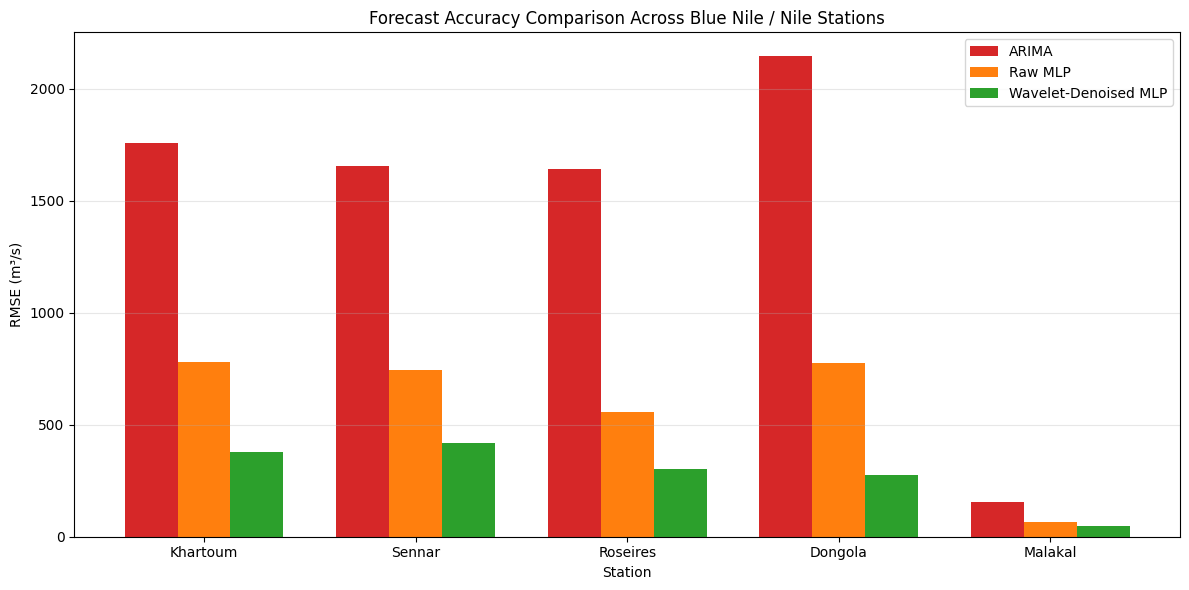

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

stations = ["Khartoum", "Sennar", "Roseires", "Dongola", "Malakal"]
arima_rmse = [1756.17, 1654.23, 1640.61, 2145.24, 155.07]
raw_mlp_rmse = [780.42, 742.98, 555.67, 776.10, 64.04]
wavelet_mlp_rmse = [378.75, 418.56, 303.31, 274.50, 49.41]

x = np.arange(len(stations))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x - width, arima_rmse, width, label='ARIMA', color='#d62728')
ax.bar(x, raw_mlp_rmse, width, label='Raw MLP', color='#ff7f0e')
ax.bar(x + width, wavelet_mlp_rmse, width, label='Wavelet-Denoised MLP', color='#2ca02c')

ax.set_xlabel('Station')
ax.set_ylabel('RMSE (m³/s)')
ax.set_title('Forecast Accuracy Comparison Across Blue Nile / Nile Stations')
ax.set_xticks(x)
ax.set_xticklabels(stations)
ax.legend()
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
def run_missing_data_test(filename, station_name, missing_ratios=[0.0, 0.1, 0.2, 0.3, 0.4]):
    df = pd.read_csv(filename, sep=";", skiprows=39,
                      names=["date", "time", "original", "calculated", "flag"],
                      na_values=[-999.000, "-999.000"], encoding="latin-1")
    df["discharge_filled"] = df["original"].interpolate(method="linear")
    full_signal = df["discharge_filled"].dropna().values

    results = []

    for ratio in missing_ratios:
        # Create a copy and artificially knock out `ratio` fraction of points (random)
        np.random.seed(42)
        signal_with_gaps = full_signal.copy()
        n_missing = int(len(signal_with_gaps) * ratio)
        missing_idx = np.random.choice(len(signal_with_gaps), n_missing, replace=False)
        signal_with_gaps[missing_idx] = np.nan

        # Interpolate to fill (simulating realistic reconstruction)
        signal_filled = pd.Series(signal_with_gaps).interpolate(method="linear").bfill().ffill().values

        # Wavelet denoise
        coeffs = pywt.wavedec(signal_filled, 'db4', level=4)
        threshold = np.std(coeffs[-1]) * 2
        denoised_coeffs = coeffs.copy()
        denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')
        denoised_signal = pywt.waverec(denoised_coeffs, 'db4')[:len(signal_filled)]

        # Lag features
        X_raw, y_raw = create_lagged_features(signal_filled, n_lags=12)
        X_den, y_den = create_lagged_features(denoised_signal, n_lags=12)

        split_idx = int(len(X_raw) * 0.8)
        X_raw_train, X_raw_test = X_raw[:split_idx], X_raw[split_idx:]
        y_raw_train, y_raw_test = y_raw[:split_idx], y_raw[split_idx:]
        X_den_train, X_den_test = X_den[:split_idx], X_den[split_idx:]
        y_den_train, y_den_test = y_den[:split_idx], y_den[split_idx:]

        model_raw = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
        model_raw.fit(X_raw_train, y_raw_train)
        pred_raw = model_raw.predict(X_raw_test)

        model_den = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
        model_den.fit(X_den_train, y_den_train)
        pred_den = model_den.predict(X_den_test)

        rmse_raw = np.sqrt(mean_squared_error(y_raw_test, pred_raw))
        rmse_den = np.sqrt(mean_squared_error(y_den_test, pred_den))
        r2_raw = r2_score(y_raw_test, pred_raw)
        r2_den = r2_score(y_den_test, pred_den)

        print(f"{station_name} @ {int(ratio*100)}% missing -> Raw RMSE={rmse_raw:.1f} R²={r2_raw:.3f} | Denoised RMSE={rmse_den:.1f} R²={r2_den:.3f}")

        results.append({"station": station_name, "missing_pct": ratio*100,
                        "rmse_raw": rmse_raw, "rmse_den": rmse_den,
                        "r2_raw": r2_raw, "r2_den": r2_den})
    return results

# Run on Khartoum first as the primary test case
khartoum_robustness = run_missing_data_test("Khartoum.txt", "Khartoum")

Khartoum @ 0% missing -> Raw RMSE=780.4 R²=0.793 | Denoised RMSE=378.7 R²=0.949
Khartoum @ 10% missing -> Raw RMSE=734.9 R²=0.791 | Denoised RMSE=278.3 R²=0.969
Khartoum @ 20% missing -> Raw RMSE=715.0 R²=0.781 | Denoised RMSE=253.6 R²=0.971
Khartoum @ 30% missing -> Raw RMSE=854.1 R²=0.653 | Denoised RMSE=301.0 R²=0.955
Khartoum @ 40% missing -> Raw RMSE=893.5 R²=0.607 | Denoised RMSE=331.7 R²=0.943


In [ ]:
all_robustness_results = []

for filename, station_name in [("Khartoum.txt", "Khartoum"),
                                  ("Sennar.txt", "Sennar"),
                                  ("Roseires.txt", "Roseires"),
                                  ("Dongola.txt", "Dongola"),
                                  ("Malakal.txt", "Malakal")]:
    print(f"\n--- Running {station_name} ---")
    station_results = run_missing_data_test(filename, station_name)
    all_robustness_results.extend(station_results)


--- Running Khartoum ---
Khartoum @ 0% missing -> Raw RMSE=780.4 R²=0.793 | Denoised RMSE=378.7 R²=0.949
Khartoum @ 10% missing -> Raw RMSE=734.9 R²=0.791 | Denoised RMSE=278.3 R²=0.969
Khartoum @ 20% missing -> Raw RMSE=715.0 R²=0.781 | Denoised RMSE=253.6 R²=0.971
Khartoum @ 30% missing -> Raw RMSE=854.1 R²=0.653 | Denoised RMSE=301.0 R²=0.955
Khartoum @ 40% missing -> Raw RMSE=893.5 R²=0.607 | Denoised RMSE=331.7 R²=0.943

--- Running Sennar ---
Sennar @ 0% missing -> Raw RMSE=743.0 R²=0.784 | Denoised RMSE=418.6 R²=0.927
Sennar @ 10% missing -> Raw RMSE=706.9 R²=0.799 | Denoised RMSE=351.7 R²=0.947
Sennar @ 20% missing -> Raw RMSE=736.1 R²=0.773 | Denoised RMSE=376.1 R²=0.937
Sennar @ 30% missing -> Raw RMSE=789.3 R²=0.728 | Denoised RMSE=397.0 R²=0.928
Sennar @ 40% missing -> Raw RMSE=863.1 R²=0.664 | Denoised RMSE=432.5 R²=0.911

--- Running Roseires ---
Roseires @ 0% missing -> Raw RMSE=555.7 R²=0.883 | Denoised RMSE=303.3 R²=0.963
Roseires @ 10% missing -> Raw RMSE=606.4 R²=0.

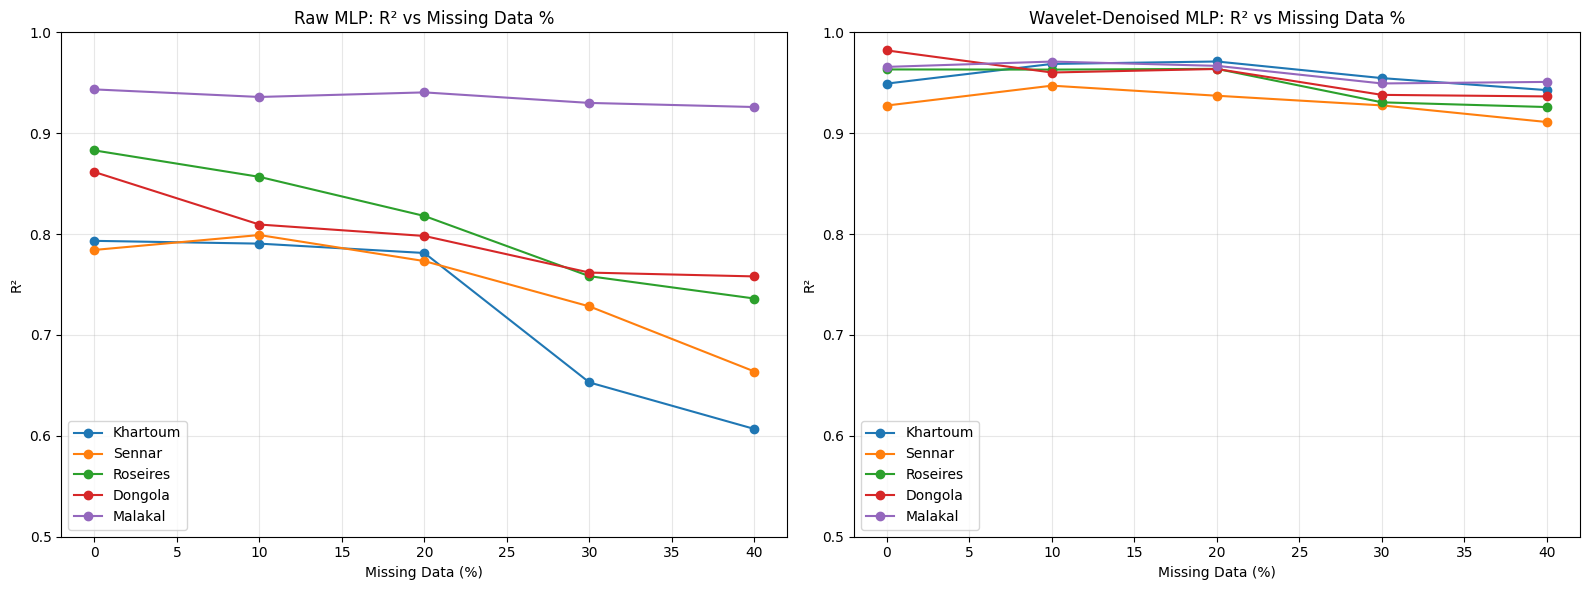

In [ ]:
import pandas as pd

df_robust = pd.DataFrame(all_robustness_results)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: R² degradation for Raw MLP
for station in df_robust["station"].unique():
    subset = df_robust[df_robust["station"] == station]
    axes[0].plot(subset["missing_pct"], subset["r2_raw"], marker='o', label=station)

axes[0].set_title("Raw MLP: R² vs Missing Data %")
axes[0].set_xlabel("Missing Data (%)")
axes[0].set_ylabel("R²")
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim(0.5, 1.0)

# Plot 2: R² degradation for Wavelet-Denoised MLP
for station in df_robust["station"].unique():
    subset = df_robust[df_robust["station"] == station]
    axes[1].plot(subset["missing_pct"], subset["r2_den"], marker='o', label=station)

axes[1].set_title("Wavelet-Denoised MLP: R² vs Missing Data %")
axes[1].set_xlabel("Missing Data (%)")
axes[1].set_ylabel("R²")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim(0.5, 1.0)

plt.tight_layout()
plt.show()

In [ ]:
def nse(observed, predicted):
    return 1 - (np.sum((observed - predicted)**2) / np.sum((observed - np.mean(observed))**2))

def kge(observed, predicted):
    r = np.corrcoef(observed, predicted)[0, 1]
    alpha = np.std(predicted) / np.std(observed)
    beta = np.mean(predicted) / np.mean(observed)
    return 1 - np.sqrt((r-1)**2 + (alpha-1)**2 + (beta-1)**2)

def run_full_comparison(filename, station_name):
    df = pd.read_csv(filename, sep=";", skiprows=39,
                      names=["date", "time", "original", "calculated", "flag"],
                      na_values=[-999.000, "-999.000"], encoding="latin-1")
    df["discharge_filled"] = df["original"].interpolate(method="linear")
    signal = df["discharge_filled"].dropna().values

    coeffs = pywt.wavedec(signal, 'db4', level=4)
    threshold = np.std(coeffs[-1]) * 2
    denoised_coeffs = coeffs.copy()
    denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')
    denoised_signal = pywt.waverec(denoised_coeffs, 'db4')[:len(signal)]

    X_raw, y_raw = create_lagged_features(signal, n_lags=12)
    X_den, y_den = create_lagged_features(denoised_signal, n_lags=12)

    split_idx = int(len(X_raw) * 0.8)
    X_raw_train, X_raw_test = X_raw[:split_idx], X_raw[split_idx:]
    y_raw_train, y_raw_test = y_raw[:split_idx], y_raw[split_idx:]
    X_den_train, X_den_test = X_den[:split_idx], X_den[split_idx:]
    y_den_train, y_den_test = y_den[:split_idx], y_den[split_idx:]

    # Naive persistence baseline: predict = last known value (last column of X)
    pred_naive = X_raw_test[:, -1]

    # Raw MLP
    model_raw = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
    model_raw.fit(X_raw_train, y_raw_train)
    pred_raw = model_raw.predict(X_raw_test)

    # Wavelet-denoised MLP
    model_den = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
    model_den.fit(X_den_train, y_den_train)
    pred_den = model_den.predict(X_den_test)

    results = {}
    for name, y_true, y_pred in [("Naive", y_raw_test, pred_naive),
                                    ("Raw MLP", y_raw_test, pred_raw),
                                    ("Wavelet MLP", y_den_test, pred_den)]:
        results[name] = {
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred),
            "NSE": nse(y_true, y_pred),
            "KGE": kge(y_true, y_pred)
        }

    print(f"\n=== {station_name} ===")
    for model_name, metrics in results.items():
        print(f"{model_name:12s}: RMSE={metrics['RMSE']:.2f}  R²={metrics['R2']:.3f}  NSE={metrics['NSE']:.3f}  KGE={metrics['KGE']:.3f}")

    return {"station": station_name, **{f"{m}_{k}": v[k] for m, v in results.items() for k in v}}

full_results = []
for filename, station_name in [("Khartoum.txt", "Khartoum"), ("Sennar.txt", "Sennar"),
                                  ("Roseires.txt", "Roseires"), ("Dongola.txt", "Dongola"),
                                  ("Malakal.txt", "Malakal")]:
    full_results.append(run_full_comparison(filename, station_name))


=== Khartoum ===
Naive       : RMSE=1512.25  R²=0.224  NSE=0.224  KGE=0.612
Raw MLP     : RMSE=780.42  R²=0.793  NSE=0.793  KGE=0.873
Wavelet MLP : RMSE=378.75  R²=0.949  NSE=0.949  KGE=0.958

=== Sennar ===
Naive       : RMSE=1414.37  R²=0.218  NSE=0.218  KGE=0.609
Raw MLP     : RMSE=742.98  R²=0.784  NSE=0.784  KGE=0.844
Wavelet MLP : RMSE=418.56  R²=0.927  NSE=0.927  KGE=0.943

=== Roseires ===
Naive       : RMSE=1359.02  R²=0.300  NSE=0.300  KGE=0.650
Raw MLP     : RMSE=555.67  R²=0.883  NSE=0.883  KGE=0.915
Wavelet MLP : RMSE=303.31  R²=0.963  NSE=0.963  KGE=0.977

=== Dongola ===
Naive       : RMSE=1792.40  R²=0.262  NSE=0.262  KGE=0.630
Raw MLP     : RMSE=776.10  R²=0.862  NSE=0.862  KGE=0.886
Wavelet MLP : RMSE=274.50  R²=0.982  NSE=0.982  KGE=0.969

=== Malakal ===
Naive       : RMSE=150.32  R²=0.688  NSE=0.688  KGE=0.844
Raw MLP     : RMSE=64.04  R²=0.943  NSE=0.943  KGE=0.956
Wavelet MLP : RMSE=49.41  R²=0.966  NSE=0.966  KGE=0.967


In [ ]:
def wavelet_energy_analysis(filename, station_name):
    df = pd.read_csv(filename, sep=";", skiprows=39,
                      names=["date", "time", "original", "calculated", "flag"],
                      na_values=[-999.000, "-999.000"], encoding="latin-1")
    df["discharge_filled"] = df["original"].interpolate(method="linear")
    signal = df["discharge_filled"].dropna().values

    coeffs = pywt.wavedec(signal, 'db4', level=4)

    # Energy = sum of squares of coefficients at each level
    energies = [np.sum(c**2) for c in coeffs]
    total_energy = sum(energies)
    energy_pct = [e/total_energy*100 for e in energies]

    labels = ["Trend (A4)", "D4", "D3", "D2", "D1 (Noise)"]

    print(f"\n=== {station_name} - Energy Distribution ===")
    for label, pct in zip(labels, energy_pct):
        print(f"{label:15s}: {pct:.2f}%")

    # Coefficient of variation of raw signal (measure of variability/seasonality strength)
    cv = np.std(signal) / np.mean(signal)
    print(f"Coefficient of Variation: {cv:.3f}")

    # High-frequency energy (D1+D2, the "noisy/short-term" bands)
    high_freq_energy = energy_pct[-1] + energy_pct[-2]
    print(f"High-frequency energy (D1+D2): {high_freq_energy:.2f}%")

    return {"station": station_name, "cv": cv, "high_freq_energy": high_freq_energy,
            "trend_energy": energy_pct[0], "energies": energy_pct}

energy_results = []
for filename, station_name in [("Khartoum.txt", "Khartoum"), ("Sennar.txt", "Sennar"),
                                  ("Roseires.txt", "Roseires"), ("Dongola.txt", "Dongola"),
                                  ("Malakal.txt", "Malakal")]:
    energy_results.append(wavelet_energy_analysis(filename, station_name))


=== Khartoum - Energy Distribution ===
Trend (A4)     : 37.93%
D4             : 3.77%
D3             : 27.37%
D2             : 29.51%
D1 (Noise)     : 1.42%
Coefficient of Variation: 1.331
High-frequency energy (D1+D2): 30.93%

=== Sennar - Energy Distribution ===
Trend (A4)     : 38.31%
D4             : 3.62%
D3             : 29.22%
D2             : 27.02%
D1 (Noise)     : 1.82%
Coefficient of Variation: 1.317
High-frequency energy (D1+D2): 28.85%

=== Roseires - Energy Distribution ===
Trend (A4)     : 41.01%
D4             : 3.29%
D3             : 29.55%
D2             : 24.28%
D1 (Noise)     : 1.87%
Coefficient of Variation: 1.228
High-frequency energy (D1+D2): 26.15%

=== Dongola - Energy Distribution ===
Trend (A4)     : 52.63%
D4             : 2.61%
D3             : 18.78%
D2             : 24.69%
D1 (Noise)     : 1.30%
Coefficient of Variation: 0.984
High-frequency energy (D1+D2): 25.99%

=== Malakal - Energy Distribution ===
Trend (A4)     : 92.35%
D4             : 0.63%
D3   

In [ ]:
def run_block_missing_test(filename, station_name, block_sizes_pct=[0.0, 0.1, 0.2, 0.3, 0.4]):
    df = pd.read_csv(filename, sep=";", skiprows=39,
                      names=["date", "time", "original", "calculated", "flag"],
                      na_values=[-999.000, "-999.000"], encoding="latin-1")
    df["discharge_filled"] = df["original"].interpolate(method="linear")
    full_signal = df["discharge_filled"].dropna().values

    results = []

    for pct in block_sizes_pct:
        np.random.seed(42)
        signal_with_gaps = full_signal.copy()
        n_total_missing = int(len(signal_with_gaps) * pct)

        if n_total_missing > 0:
            # Create contiguous blocks instead of random scattered points
            block_length = 12  # simulate ~1 year outages
            n_blocks = max(1, n_total_missing // block_length)

            for _ in range(n_blocks):
                start = np.random.randint(0, len(signal_with_gaps) - block_length)
                signal_with_gaps[start:start+block_length] = np.nan

        # Interpolate to fill (simulating realistic reconstruction)
        signal_filled = pd.Series(signal_with_gaps).interpolate(method="linear").bfill().ffill().values

        # Wavelet denoise
        coeffs = pywt.wavedec(signal_filled, 'db4', level=4)
        threshold = np.std(coeffs[-1]) * 2
        denoised_coeffs = coeffs.copy()
        denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')
        denoised_signal = pywt.waverec(denoised_coeffs, 'db4')[:len(signal_filled)]

        # Lag features
        X_raw, y_raw = create_lagged_features(signal_filled, n_lags=12)
        X_den, y_den = create_lagged_features(denoised_signal, n_lags=12)

        split_idx = int(len(X_raw) * 0.8)
        X_raw_train, X_raw_test = X_raw[:split_idx], X_raw[split_idx:]
        y_raw_train, y_raw_test = y_raw[:split_idx], y_raw[split_idx:]
        X_den_train, X_den_test = X_den[:split_idx], X_den[split_idx:]
        y_den_train, y_den_test = y_den[:split_idx], y_den[split_idx:]

        model_raw = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
        model_raw.fit(X_raw_train, y_raw_train)
        pred_raw = model_raw.predict(X_raw_test)

        model_den = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
        model_den.fit(X_den_train, y_den_train)
        pred_den = model_den.predict(X_den_test)

        nse_raw = nse(y_raw_test, pred_raw)
        nse_den = nse(y_den_test, pred_den)

        print(f"{station_name} @ {int(pct*100)}% block-missing -> Raw NSE={nse_raw:.3f} | Denoised NSE={nse_den:.3f}")

        results.append({"station": station_name, "missing_pct": pct*100,
                        "nse_raw": nse_raw, "nse_den": nse_den})
    return results

all_block_results = []
for filename, station_name in [("Khartoum.txt", "Khartoum"), ("Sennar.txt", "Sennar"),
                                  ("Roseires.txt", "Roseires"), ("Dongola.txt", "Dongola"),
                                  ("Malakal.txt", "Malakal")]:
    print(f"\n--- {station_name} ---")
    all_block_results.extend(run_block_missing_test(filename, station_name))


--- Khartoum ---
Khartoum @ 0% block-missing -> Raw NSE=0.793 | Denoised NSE=0.949
Khartoum @ 10% block-missing -> Raw NSE=0.788 | Denoised NSE=0.923
Khartoum @ 20% block-missing -> Raw NSE=0.814 | Denoised NSE=0.928
Khartoum @ 30% block-missing -> Raw NSE=0.845 | Denoised NSE=0.922
Khartoum @ 40% block-missing -> Raw NSE=0.815 | Denoised NSE=0.931

--- Sennar ---
Sennar @ 0% block-missing -> Raw NSE=0.784 | Denoised NSE=0.927
Sennar @ 10% block-missing -> Raw NSE=0.766 | Denoised NSE=0.904
Sennar @ 20% block-missing -> Raw NSE=0.758 | Denoised NSE=0.889
Sennar @ 30% block-missing -> Raw NSE=0.751 | Denoised NSE=0.892
Sennar @ 40% block-missing -> Raw NSE=0.733 | Denoised NSE=0.866

--- Roseires ---
Roseires @ 0% block-missing -> Raw NSE=0.883 | Denoised NSE=0.963
Roseires @ 10% block-missing -> Raw NSE=0.850 | Denoised NSE=0.940
Roseires @ 20% block-missing -> Raw NSE=0.851 | Denoised NSE=0.943
Roseires @ 30% block-missing -> Raw NSE=0.843 | Denoised NSE=0.935
Roseires @ 40% block-mi

In [ ]:
from sklearn.ensemble import RandomForestRegressor

def run_rf_comparison(filename, station_name):
    df = pd.read_csv(filename, sep=";", skiprows=39,
                      names=["date", "time", "original", "calculated", "flag"],
                      na_values=[-999.000, "-999.000"], encoding="latin-1")
    df["discharge_filled"] = df["original"].interpolate(method="linear")
    signal = df["discharge_filled"].dropna().values

    coeffs = pywt.wavedec(signal, 'db4', level=4)
    threshold = np.std(coeffs[-1]) * 2
    denoised_coeffs = coeffs.copy()
    denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')
    denoised_signal = pywt.waverec(denoised_coeffs, 'db4')[:len(signal)]

    X_raw, y_raw = create_lagged_features(signal, n_lags=12)
    X_den, y_den = create_lagged_features(denoised_signal, n_lags=12)

    split_idx = int(len(X_raw) * 0.8)
    X_raw_train, X_raw_test = X_raw[:split_idx], X_raw[split_idx:]
    y_raw_train, y_raw_test = y_raw[:split_idx], y_raw[split_idx:]
    X_den_train, X_den_test = X_den[:split_idx], X_den[split_idx:]
    y_den_train, y_den_test = y_den[:split_idx], y_den[split_idx:]

    # Random Forest on raw data
    rf_raw = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42)
    rf_raw.fit(X_raw_train, y_raw_train)
    pred_rf_raw = rf_raw.predict(X_raw_test)

    # Random Forest on wavelet-denoised data
    rf_den = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42)
    rf_den.fit(X_den_train, y_den_train)
    pred_rf_den = rf_den.predict(X_den_test)

    nse_rf_raw = nse(y_raw_test, pred_rf_raw)
    nse_rf_den = nse(y_den_test, pred_rf_den)
    rmse_rf_raw = np.sqrt(mean_squared_error(y_raw_test, pred_rf_raw))
    rmse_rf_den = np.sqrt(mean_squared_error(y_den_test, pred_rf_den))

    print(f"{station_name}: RF-Raw NSE={nse_rf_raw:.3f} RMSE={rmse_rf_raw:.1f} | RF-Wavelet NSE={nse_rf_den:.3f} RMSE={rmse_rf_den:.1f}")

    return {"station": station_name, "nse_rf_raw": nse_rf_raw, "nse_rf_den": nse_rf_den,
            "rmse_rf_raw": rmse_rf_raw, "rmse_rf_den": rmse_rf_den}

rf_results = []
for filename, station_name in [("Khartoum.txt", "Khartoum"), ("Sennar.txt", "Sennar"),
                                  ("Roseires.txt", "Roseires"), ("Dongola.txt", "Dongola"),
                                  ("Malakal.txt", "Malakal")]:
    rf_results.append(run_rf_comparison(filename, station_name))

Khartoum: RF-Raw NSE=0.826 RMSE=716.8 | RF-Wavelet NSE=0.901 RMSE=528.6
Sennar: RF-Raw NSE=0.854 RMSE=611.6 | RF-Wavelet NSE=0.820 RMSE=659.9
Roseires: RF-Raw NSE=0.874 RMSE=577.6 | RF-Wavelet NSE=0.879 RMSE=550.7
Dongola: RF-Raw NSE=0.810 RMSE=909.2 | RF-Wavelet NSE=0.881 RMSE=707.5
Malakal: RF-Raw NSE=0.914 RMSE=78.8 | RF-Wavelet NSE=0.954 RMSE=57.3


In [ ]:
def load_signal(filename):
    df = pd.read_csv(filename, sep=";", skiprows=39,
                      names=["date", "time", "original", "calculated", "flag"],
                      na_values=[-999.000, "-999.000"], encoding="latin-1")
    df["discharge_filled"] = df["original"].interpolate(method="linear")
    return df["discharge_filled"].dropna().values

def normalize(signal):
    # Normalize by mean flow so different-sized rivers are comparable
    return signal / np.mean(signal)

# Load and normalize all training stations (Blue Nile system, excluding Khartoum)
train_stations = ["Sennar.txt", "Roseires.txt", "Dongola.txt"]
test_station = "Khartoum.txt"

X_train_all_raw, y_train_all_raw = [], []
X_train_all_den, y_train_all_den = [], []

for filename in train_stations:
    signal = load_signal(filename)
    signal_norm = normalize(signal)

    coeffs = pywt.wavedec(signal_norm, 'db4', level=4)
    threshold = np.std(coeffs[-1]) * 2
    denoised_coeffs = coeffs.copy()
    denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')
    denoised_signal = pywt.waverec(denoised_coeffs, 'db4')[:len(signal_norm)]

    X_raw, y_raw = create_lagged_features(signal_norm, n_lags=12)
    X_den, y_den = create_lagged_features(denoised_signal, n_lags=12)

    X_train_all_raw.append(X_raw)
    y_train_all_raw.append(y_raw)
    X_train_all_den.append(X_den)
    y_train_all_den.append(y_den)

X_train_all_raw = np.vstack(X_train_all_raw)
y_train_all_raw = np.concatenate(y_train_all_raw)
X_train_all_den = np.vstack(X_train_all_den)
y_train_all_den = np.concatenate(y_train_all_den)

# Load and normalize the UNSEEN test station (Khartoum) - never used in training
test_signal = load_signal(test_station)
test_signal_norm = normalize(test_signal)

test_coeffs = pywt.wavedec(test_signal_norm, 'db4', level=4)
test_threshold = np.std(test_coeffs[-1]) * 2
test_denoised_coeffs = test_coeffs.copy()
test_denoised_coeffs[-1] = pywt.threshold(test_coeffs[-1], test_threshold, mode='soft')
test_denoised_signal = pywt.waverec(test_denoised_coeffs, 'db4')[:len(test_signal_norm)]

X_test_raw, y_test_raw = create_lagged_features(test_signal_norm, n_lags=12)
X_test_den, y_test_den = create_lagged_features(test_denoised_signal, n_lags=12)

# Train on combined 3-station data, test on completely unseen Khartoum
model_transfer_raw = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
model_transfer_raw.fit(X_train_all_raw, y_train_all_raw)
pred_transfer_raw = model_transfer_raw.predict(X_test_raw)

model_transfer_den = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
model_transfer_den.fit(X_train_all_den, y_train_all_den)
pred_transfer_den = model_transfer_den.predict(X_test_den)

nse_transfer_raw = nse(y_test_raw, pred_transfer_raw)
nse_transfer_den = nse(y_test_den, pred_transfer_den)

print(f"UNGAUGED BASIN TRANSFER TEST (trained on Sennar+Roseires+Dongola, tested on unseen Khartoum)")
print(f"Raw MLP transfer:      NSE = {nse_transfer_raw:.3f}")
print(f"Wavelet MLP transfer:  NSE = {nse_transfer_den:.3f}")

NameError: name 'pd' is not defined

In [ ]:
def load_signal(filename):
    df = pd.read_csv(filename, sep=";", skiprows=39,
                      names=["date", "time", "original", "calculated", "flag"],
                      na_values=[-999.000, "-999.000"], encoding="latin-1")
    df["discharge_filled"] = df["original"].interpolate(method="linear")
    return df["discharge_filled"].dropna().values

def normalize(signal):
    # Normalize by mean flow so different-sized rivers are comparable
    return signal / np.mean(signal)

# Load and normalize all training stations (Blue Nile system, excluding Khartoum)
train_stations = ["Sennar.txt", "Roseires.txt", "Dongola.txt"]
test_station = "Khartoum.txt"

X_train_all_raw, y_train_all_raw = [], []
X_train_all_den, y_train_all_den = [], []

for filename in train_stations:
    signal = load_signal(filename)
    signal_norm = normalize(signal)

    coeffs = pywt.wavedec(signal_norm, 'db4', level=4)
    threshold = np.std(coeffs[-1]) * 2
    denoised_coeffs = coeffs.copy()
    denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')
    denoised_signal = pywt.waverec(denoised_coeffs, 'db4')[:len(signal_norm)]

    X_raw, y_raw = create_lagged_features(signal_norm, n_lags=12)
    X_den, y_den = create_lagged_features(denoised_signal, n_lags=12)

    X_train_all_raw.append(X_raw)
    y_train_all_raw.append(y_raw)
    X_train_all_den.append(X_den)
    y_train_all_den.append(y_den)

X_train_all_raw = np.vstack(X_train_all_raw)
y_train_all_raw = np.concatenate(y_train_all_raw)
X_train_all_den = np.vstack(X_train_all_den)
y_train_all_den = np.concatenate(y_train_all_den)

# Load and normalize the UNSEEN test station (Khartoum) - never used in training
test_signal = load_signal(test_station)
test_signal_norm = normalize(test_signal)

test_coeffs = pywt.wavedec(test_signal_norm, 'db4', level=4)
test_threshold = np.std(test_coeffs[-1]) * 2
test_denoised_coeffs = test_coeffs.copy()
test_denoised_coeffs[-1] = pywt.threshold(test_coeffs[-1], test_threshold, mode='soft')
test_denoised_signal = pywt.waverec(test_denoised_coeffs, 'db4')[:len(test_signal_norm)]

X_test_raw, y_test_raw = create_lagged_features(test_signal_norm, n_lags=12)
X_test_den, y_test_den = create_lagged_features(test_denoised_signal, n_lags=12)

# Train on combined 3-station data, test on completely unseen Khartoum
model_transfer_raw = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
model_transfer_raw.fit(X_train_all_raw, y_train_all_raw)
pred_transfer_raw = model_transfer_raw.predict(X_test_raw)

model_transfer_den = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
model_transfer_den.fit(X_train_all_den, y_train_all_den)
pred_transfer_den = model_transfer_den.predict(X_test_den)

nse_transfer_raw = nse(y_test_raw, pred_transfer_raw)
nse_transfer_den = nse(y_test_den, pred_transfer_den)

print(f"UNGAUGED BASIN TRANSFER TEST (trained on Sennar+Roseires+Dongola, tested on unseen Khartoum)")
print(f"Raw MLP transfer:      NSE = {nse_transfer_raw:.3f}")
print(f"Wavelet MLP transfer:  NSE = {nse_transfer_den:.3f}")

NameError: name 'pd' is not defined

In [1]:
def load_signal(filename):
    df = pd.read_csv(filename, sep=";", skiprows=39,
                      names=["date", "time", "original", "calculated", "flag"],
                      na_values=[-999.000, "-999.000"], encoding="latin-1")
    df["discharge_filled"] = df["original"].interpolate(method="linear")
    return df["discharge_filled"].dropna().values

def normalize(signal):
    # Normalize by mean flow so different-sized rivers are comparable
    return signal / np.mean(signal)

# Load and normalize all training stations (Blue Nile system, excluding Khartoum)
train_stations = ["Sennar.txt", "Roseires.txt", "Dongola.txt"]
test_station = "Khartoum.txt"

X_train_all_raw, y_train_all_raw = [], []
X_train_all_den, y_train_all_den = [], []

for filename in train_stations:
    signal = load_signal(filename)
    signal_norm = normalize(signal)

    coeffs = pywt.wavedec(signal_norm, 'db4', level=4)
    threshold = np.std(coeffs[-1]) * 2
    denoised_coeffs = coeffs.copy()
    denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')
    denoised_signal = pywt.waverec(denoised_coeffs, 'db4')[:len(signal_norm)]

    X_raw, y_raw = create_lagged_features(signal_norm, n_lags=12)
    X_den, y_den = create_lagged_features(denoised_signal, n_lags=12)

    X_train_all_raw.append(X_raw)
    y_train_all_raw.append(y_raw)
    X_train_all_den.append(X_den)
    y_train_all_den.append(y_den)

X_train_all_raw = np.vstack(X_train_all_raw)
y_train_all_raw = np.concatenate(y_train_all_raw)
X_train_all_den = np.vstack(X_train_all_den)
y_train_all_den = np.concatenate(y_train_all_den)

# Load and normalize the UNSEEN test station (Khartoum) - never used in training
test_signal = load_signal(test_station)
test_signal_norm = normalize(test_signal)

test_coeffs = pywt.wavedec(test_signal_norm, 'db4', level=4)
test_threshold = np.std(test_coeffs[-1]) * 2
test_denoised_coeffs = test_coeffs.copy()
test_denoised_coeffs[-1] = pywt.threshold(test_coeffs[-1], test_threshold, mode='soft')
test_denoised_signal = pywt.waverec(test_denoised_coeffs, 'db4')[:len(test_signal_norm)]

X_test_raw, y_test_raw = create_lagged_features(test_signal_norm, n_lags=12)
X_test_den, y_test_den = create_lagged_features(test_denoised_signal, n_lags=12)

# Train on combined 3-station data, test on completely unseen Khartoum
model_transfer_raw = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
model_transfer_raw.fit(X_train_all_raw, y_train_all_raw)
pred_transfer_raw = model_transfer_raw.predict(X_test_raw)

model_transfer_den = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
model_transfer_den.fit(X_train_all_den, y_train_all_den)
pred_transfer_den = model_transfer_den.predict(X_test_den)

nse_transfer_raw = nse(y_test_raw, pred_transfer_raw)
nse_transfer_den = nse(y_test_den, pred_transfer_den)

print(f"UNGAUGED BASIN TRANSFER TEST (trained on Sennar+Roseires+Dongola, tested on unseen Khartoum)")
print(f"Raw MLP transfer:      NSE = {nse_transfer_raw:.3f}")
print(f"Wavelet MLP transfer:  NSE = {nse_transfer_den:.3f}")

NameError: name 'pd' is not defined

In [2]:
import pandas as pd
import numpy as np
import pywt
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

def create_lagged_features(data, n_lags=12):
    X, y = [], []
    for i in range(n_lags, len(data)):
        X.append(data[i-n_lags:i])
        y.append(data[i])
    return np.array(X), np.array(y)

def nse(observed, predicted):
    return 1 - (np.sum((observed - predicted)**2) / np.sum((observed - np.mean(observed))**2))

def kge(observed, predicted):
    r = np.corrcoef(observed, predicted)[0, 1]
    alpha = np.std(predicted) / np.std(observed)
    beta = np.mean(predicted) / np.mean(observed)
    return 1 - np.sqrt((r-1)**2 + (alpha-1)**2 + (beta-1)**2)

In [3]:
def load_signal(filename):
    df = pd.read_csv(filename, sep=";", skiprows=39,
                      names=["date", "time", "original", "calculated", "flag"],
                      na_values=[-999.000, "-999.000"], encoding="latin-1")
    df["discharge_filled"] = df["original"].interpolate(method="linear")
    return df["discharge_filled"].dropna().values

def normalize(signal):
    # Normalize by mean flow so different-sized rivers are comparable
    return signal / np.mean(signal)

# Load and normalize all training stations (Blue Nile system, excluding Khartoum)
train_stations = ["Sennar.txt", "Roseires.txt", "Dongola.txt"]
test_station = "Khartoum.txt"

X_train_all_raw, y_train_all_raw = [], []
X_train_all_den, y_train_all_den = [], []

for filename in train_stations:
    signal = load_signal(filename)
    signal_norm = normalize(signal)

    coeffs = pywt.wavedec(signal_norm, 'db4', level=4)
    threshold = np.std(coeffs[-1]) * 2
    denoised_coeffs = coeffs.copy()
    denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')
    denoised_signal = pywt.waverec(denoised_coeffs, 'db4')[:len(signal_norm)]

    X_raw, y_raw = create_lagged_features(signal_norm, n_lags=12)
    X_den, y_den = create_lagged_features(denoised_signal, n_lags=12)

    X_train_all_raw.append(X_raw)
    y_train_all_raw.append(y_raw)
    X_train_all_den.append(X_den)
    y_train_all_den.append(y_den)

X_train_all_raw = np.vstack(X_train_all_raw)
y_train_all_raw = np.concatenate(y_train_all_raw)
X_train_all_den = np.vstack(X_train_all_den)
y_train_all_den = np.concatenate(y_train_all_den)

# Load and normalize the UNSEEN test station (Khartoum) - never used in training
test_signal = load_signal(test_station)
test_signal_norm = normalize(test_signal)

test_coeffs = pywt.wavedec(test_signal_norm, 'db4', level=4)
test_threshold = np.std(test_coeffs[-1]) * 2
test_denoised_coeffs = test_coeffs.copy()
test_denoised_coeffs[-1] = pywt.threshold(test_coeffs[-1], test_threshold, mode='soft')
test_denoised_signal = pywt.waverec(test_denoised_coeffs, 'db4')[:len(test_signal_norm)]

X_test_raw, y_test_raw = create_lagged_features(test_signal_norm, n_lags=12)
X_test_den, y_test_den = create_lagged_features(test_denoised_signal, n_lags=12)

# Train on combined 3-station data, test on completely unseen Khartoum
model_transfer_raw = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
model_transfer_raw.fit(X_train_all_raw, y_train_all_raw)
pred_transfer_raw = model_transfer_raw.predict(X_test_raw)

model_transfer_den = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
model_transfer_den.fit(X_train_all_den, y_train_all_den)
pred_transfer_den = model_transfer_den.predict(X_test_den)

nse_transfer_raw = nse(y_test_raw, pred_transfer_raw)
nse_transfer_den = nse(y_test_den, pred_transfer_den)

print(f"UNGAUGED BASIN TRANSFER TEST (trained on Sennar+Roseires+Dongola, tested on unseen Khartoum)")
print(f"Raw MLP transfer:      NSE = {nse_transfer_raw:.3f}")
print(f"Wavelet MLP transfer:  NSE = {nse_transfer_den:.3f}")

FileNotFoundError: [Errno 2] No such file or directory: 'Sennar.txt'

In [4]:
import pandas as pd
import numpy as np
import pywt
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

def create_lagged_features(data, n_lags=12):
    X, y = [], []
    for i in range(n_lags, len(data)):
        X.append(data[i-n_lags:i])
        y.append(data[i])
    return np.array(X), np.array(y)

def nse(observed, predicted):
    return 1 - (np.sum((observed - predicted)**2) / np.sum((observed - np.mean(observed))**2))

def kge(observed, predicted):
    r = np.corrcoef(observed, predicted)[0, 1]
    alpha = np.std(predicted) / np.std(observed)
    beta = np.mean(predicted) / np.mean(observed)
    return 1 - np.sqrt((r-1)**2 + (alpha-1)**2 + (beta-1)**2)

In [5]:
def load_signal(filename):
    df = pd.read_csv(filename, sep=";", skiprows=39,
                      names=["date", "time", "original", "calculated", "flag"],
                      na_values=[-999.000, "-999.000"], encoding="latin-1")
    df["discharge_filled"] = df["original"].interpolate(method="linear")
    return df["discharge_filled"].dropna().values

def normalize(signal):
    # Normalize by mean flow so different-sized rivers are comparable
    return signal / np.mean(signal)

# Load and normalize all training stations (Blue Nile system, excluding Khartoum)
train_stations = ["Sennar.txt", "Roseires.txt", "Dongola.txt"]
test_station = "Khartoum.txt"

X_train_all_raw, y_train_all_raw = [], []
X_train_all_den, y_train_all_den = [], []

for filename in train_stations:
    signal = load_signal(filename)
    signal_norm = normalize(signal)

    coeffs = pywt.wavedec(signal_norm, 'db4', level=4)
    threshold = np.std(coeffs[-1]) * 2
    denoised_coeffs = coeffs.copy()
    denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')
    denoised_signal = pywt.waverec(denoised_coeffs, 'db4')[:len(signal_norm)]

    X_raw, y_raw = create_lagged_features(signal_norm, n_lags=12)
    X_den, y_den = create_lagged_features(denoised_signal, n_lags=12)

    X_train_all_raw.append(X_raw)
    y_train_all_raw.append(y_raw)
    X_train_all_den.append(X_den)
    y_train_all_den.append(y_den)

X_train_all_raw = np.vstack(X_train_all_raw)
y_train_all_raw = np.concatenate(y_train_all_raw)
X_train_all_den = np.vstack(X_train_all_den)
y_train_all_den = np.concatenate(y_train_all_den)

# Load and normalize the UNSEEN test station (Khartoum) - never used in training
test_signal = load_signal(test_station)
test_signal_norm = normalize(test_signal)

test_coeffs = pywt.wavedec(test_signal_norm, 'db4', level=4)
test_threshold = np.std(test_coeffs[-1]) * 2
test_denoised_coeffs = test_coeffs.copy()
test_denoised_coeffs[-1] = pywt.threshold(test_coeffs[-1], test_threshold, mode='soft')
test_denoised_signal = pywt.waverec(test_denoised_coeffs, 'db4')[:len(test_signal_norm)]

X_test_raw, y_test_raw = create_lagged_features(test_signal_norm, n_lags=12)
X_test_den, y_test_den = create_lagged_features(test_denoised_signal, n_lags=12)

# Train on combined 3-station data, test on completely unseen Khartoum
model_transfer_raw = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
model_transfer_raw.fit(X_train_all_raw, y_train_all_raw)
pred_transfer_raw = model_transfer_raw.predict(X_test_raw)

model_transfer_den = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
model_transfer_den.fit(X_train_all_den, y_train_all_den)
pred_transfer_den = model_transfer_den.predict(X_test_den)

nse_transfer_raw = nse(y_test_raw, pred_transfer_raw)
nse_transfer_den = nse(y_test_den, pred_transfer_den)

print(f"UNGAUGED BASIN TRANSFER TEST (trained on Sennar+Roseires+Dongola, tested on unseen Khartoum)")
print(f"Raw MLP transfer:      NSE = {nse_transfer_raw:.3f}")
print(f"Wavelet MLP transfer:  NSE = {nse_transfer_den:.3f}")

UNGAUGED BASIN TRANSFER TEST (trained on Sennar+Roseires+Dongola, tested on unseen Khartoum)
Raw MLP transfer:      NSE = 0.932
Wavelet MLP transfer:  NSE = 0.981


In [6]:
# Load and normalize training stations (Blue Nile system only)
train_stations_blue = ["Sennar.txt", "Roseires.txt"]
test_station_white = "Malakal.txt"

X_train_blue_raw, y_train_blue_raw = [], []
X_train_blue_den, y_train_blue_den = [], []

for filename in train_stations_blue:
    signal = load_signal(filename)
    signal_norm = normalize(signal)

    coeffs = pywt.wavedec(signal_norm, 'db4', level=4)
    threshold = np.std(coeffs[-1]) * 2
    denoised_coeffs = coeffs.copy()
    denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')
    denoised_signal = pywt.waverec(denoised_coeffs, 'db4')[:len(signal_norm)]

    X_raw, y_raw = create_lagged_features(signal_norm, n_lags=12)
    X_den, y_den = create_lagged_features(denoised_signal, n_lags=12)

    X_train_blue_raw.append(X_raw)
    y_train_blue_raw.append(y_raw)
    X_train_blue_den.append(X_den)
    y_train_blue_den.append(y_den)

X_train_blue_raw = np.vstack(X_train_blue_raw)
y_train_blue_raw = np.concatenate(y_train_blue_raw)
X_train_blue_den = np.vstack(X_train_blue_den)
y_train_blue_den = np.concatenate(y_train_blue_den)

# Load and normalize the UNSEEN test station (Malakal, White Nile - different sub-basin)
test_signal_white = load_signal(test_station_white)
test_signal_white_norm = normalize(test_signal_white)

test_coeffs_white = pywt.wavedec(test_signal_white_norm, 'db4', level=4)
test_threshold_white = np.std(test_coeffs_white[-1]) * 2
test_denoised_coeffs_white = test_coeffs_white.copy()
test_denoised_coeffs_white[-1] = pywt.threshold(test_coeffs_white[-1], test_threshold_white, mode='soft')
test_denoised_signal_white = pywt.waverec(test_denoised_coeffs_white, 'db4')[:len(test_signal_white_norm)]

X_test_white_raw, y_test_white_raw = create_lagged_features(test_signal_white_norm, n_lags=12)
X_test_white_den, y_test_white_den = create_lagged_features(test_denoised_signal_white, n_lags=12)

# Train on Blue Nile only, test on White Nile (genuinely different sub-basin)
model_cross_raw = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
model_cross_raw.fit(X_train_blue_raw, y_train_blue_raw)
pred_cross_raw = model_cross_raw.predict(X_test_white_raw)

model_cross_den = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
model_cross_den.fit(X_train_blue_den, y_train_blue_den)
pred_cross_den = model_cross_den.predict(X_test_white_den)

nse_cross_raw = nse(y_test_white_raw, pred_cross_raw)
nse_cross_den = nse(y_test_white_den, pred_cross_den)

print(f"CROSS-BASIN TRANSFER TEST (trained on Blue Nile: Sennar+Roseires, tested on White Nile: Malakal)")
print(f"Raw MLP transfer:      NSE = {nse_cross_raw:.3f}")
print(f"Wavelet MLP transfer:  NSE = {nse_cross_den:.3f}")

CROSS-BASIN TRANSFER TEST (trained on Blue Nile: Sennar+Roseires, tested on White Nile: Malakal)
Raw MLP transfer:      NSE = 0.114
Wavelet MLP transfer:  NSE = 0.189


In [7]:
from scipy.stats import wilcoxon

def run_significance_test(filename, station_name):
    signal = load_signal(filename)

    coeffs = pywt.wavedec(signal, 'db4', level=4)
    threshold = np.std(coeffs[-1]) * 2
    denoised_coeffs = coeffs.copy()
    denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')
    denoised_signal = pywt.waverec(denoised_coeffs, 'db4')[:len(signal)]

    X_raw, y_raw = create_lagged_features(signal, n_lags=12)
    X_den, y_den = create_lagged_features(denoised_signal, n_lags=12)

    split_idx = int(len(X_raw) * 0.8)
    X_raw_train, X_raw_test = X_raw[:split_idx], X_raw[split_idx:]
    y_raw_train, y_raw_test = y_raw[:split_idx], y_raw[split_idx:]
    X_den_train, X_den_test = X_den[:split_idx], X_den[split_idx:]
    y_den_train, y_den_test = y_den[:split_idx], y_den[split_idx:]

    model_raw = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
    model_raw.fit(X_raw_train, y_raw_train)
    pred_raw = model_raw.predict(X_raw_test)

    model_den = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
    model_den.fit(X_den_train, y_den_train)
    pred_den = model_den.predict(X_den_test)

    # Absolute errors for each model (paired by time)
    errors_raw = np.abs(y_raw_test - pred_raw)
    errors_den = np.abs(y_den_test - pred_den)

    # Wilcoxon signed-rank test: is wavelet-MLP's error distribution significantly lower?
    stat, p_value = wilcoxon(errors_raw, errors_den, alternative='greater')

    significant = "YES" if p_value < 0.05 else "NO"
    print(f"{station_name}: Wilcoxon p-value = {p_value:.5f} -> Significant improvement: {significant}")

    return {"station": station_name, "p_value": p_value, "significant": significant}

sig_results = []
for filename, station_name in [("Khartoum.txt", "Khartoum"), ("Sennar.txt", "Sennar"),
                                  ("Roseires.txt", "Roseires"), ("Dongola.txt", "Dongola"),
                                  ("Malakal.txt", "Malakal")]:
    sig_results.append(run_significance_test(filename, station_name))

Khartoum: Wilcoxon p-value = 0.00000 -> Significant improvement: YES
Sennar: Wilcoxon p-value = 0.00000 -> Significant improvement: YES
Roseires: Wilcoxon p-value = 0.00000 -> Significant improvement: YES
Dongola: Wilcoxon p-value = 0.00000 -> Significant improvement: YES
Malakal: Wilcoxon p-value = 0.01138 -> Significant improvement: YES


In [8]:
def run_multihorizon_test(filename, station_name, horizons=[1, 3, 6, 12]):
    signal = load_signal(filename)

    coeffs = pywt.wavedec(signal, 'db4', level=4)
    threshold = np.std(coeffs[-1]) * 2
    denoised_coeffs = coeffs.copy()
    denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')
    denoised_signal = pywt.waverec(denoised_coeffs, 'db4')[:len(signal)]

    results = []

    for horizon in horizons:
        # Create features: use 12 months lookback, predict `horizon` months ahead
        n_lags = 12
        X_raw, y_raw = [], []
        X_den, y_den = [], []

        for i in range(n_lags, len(signal) - horizon + 1):
            X_raw.append(signal[i-n_lags:i])
            y_raw.append(signal[i+horizon-1])
            X_den.append(denoised_signal[i-n_lags:i])
            y_den.append(denoised_signal[i+horizon-1])

        X_raw, y_raw = np.array(X_raw), np.array(y_raw)
        X_den, y_den = np.array(X_den), np.array(y_den)

        split_idx = int(len(X_raw) * 0.8)
        X_raw_train, X_raw_test = X_raw[:split_idx], X_raw[split_idx:]
        y_raw_train, y_raw_test = y_raw[:split_idx], y_raw[split_idx:]
        X_den_train, X_den_test = X_den[:split_idx], X_den[split_idx:]
        y_den_train, y_den_test = y_den[:split_idx], y_den[split_idx:]

        model_raw = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
        model_raw.fit(X_raw_train, y_raw_train)
        pred_raw = model_raw.predict(X_raw_test)

        model_den = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
        model_den.fit(X_den_train, y_den_train)
        pred_den = model_den.predict(X_den_test)

        nse_raw = nse(y_raw_test, pred_raw)
        nse_den = nse(y_den_test, pred_den)

        print(f"{station_name} @ {horizon}-month horizon -> Raw NSE={nse_raw:.3f} | Wavelet NSE={nse_den:.3f}")
        results.append({"station": station_name, "horizon": horizon, "nse_raw": nse_raw, "nse_den": nse_den})

    return results

all_horizon_results = []
for filename, station_name in [("Khartoum.txt", "Khartoum"), ("Sennar.txt", "Sennar"),
                                  ("Roseires.txt", "Roseires"), ("Dongola.txt", "Dongola"),
                                  ("Malakal.txt", "Malakal")]:
    print(f"\n--- {station_name} ---")
    all_horizon_results.extend(run_multihorizon_test(filename, station_name))


--- Khartoum ---
Khartoum @ 1-month horizon -> Raw NSE=0.793 | Wavelet NSE=0.949
Khartoum @ 3-month horizon -> Raw NSE=0.762 | Wavelet NSE=0.823
Khartoum @ 6-month horizon -> Raw NSE=0.782 | Wavelet NSE=0.841
Khartoum @ 12-month horizon -> Raw NSE=0.785 | Wavelet NSE=0.859

--- Sennar ---
Sennar @ 1-month horizon -> Raw NSE=0.784 | Wavelet NSE=0.927
Sennar @ 3-month horizon -> Raw NSE=0.761 | Wavelet NSE=0.797
Sennar @ 6-month horizon -> Raw NSE=0.774 | Wavelet NSE=0.806
Sennar @ 12-month horizon -> Raw NSE=0.818 | Wavelet NSE=0.855

--- Roseires ---
Roseires @ 1-month horizon -> Raw NSE=0.883 | Wavelet NSE=0.963
Roseires @ 3-month horizon -> Raw NSE=0.849 | Wavelet NSE=0.878
Roseires @ 6-month horizon -> Raw NSE=0.850 | Wavelet NSE=0.855
Roseires @ 12-month horizon -> Raw NSE=0.865 | Wavelet NSE=0.887

--- Dongola ---
Dongola @ 1-month horizon -> Raw NSE=0.862 | Wavelet NSE=0.982
Dongola @ 3-month horizon -> Raw NSE=0.749 | Wavelet NSE=0.836
Dongola @ 6-month horizon -> Raw NSE=0.737

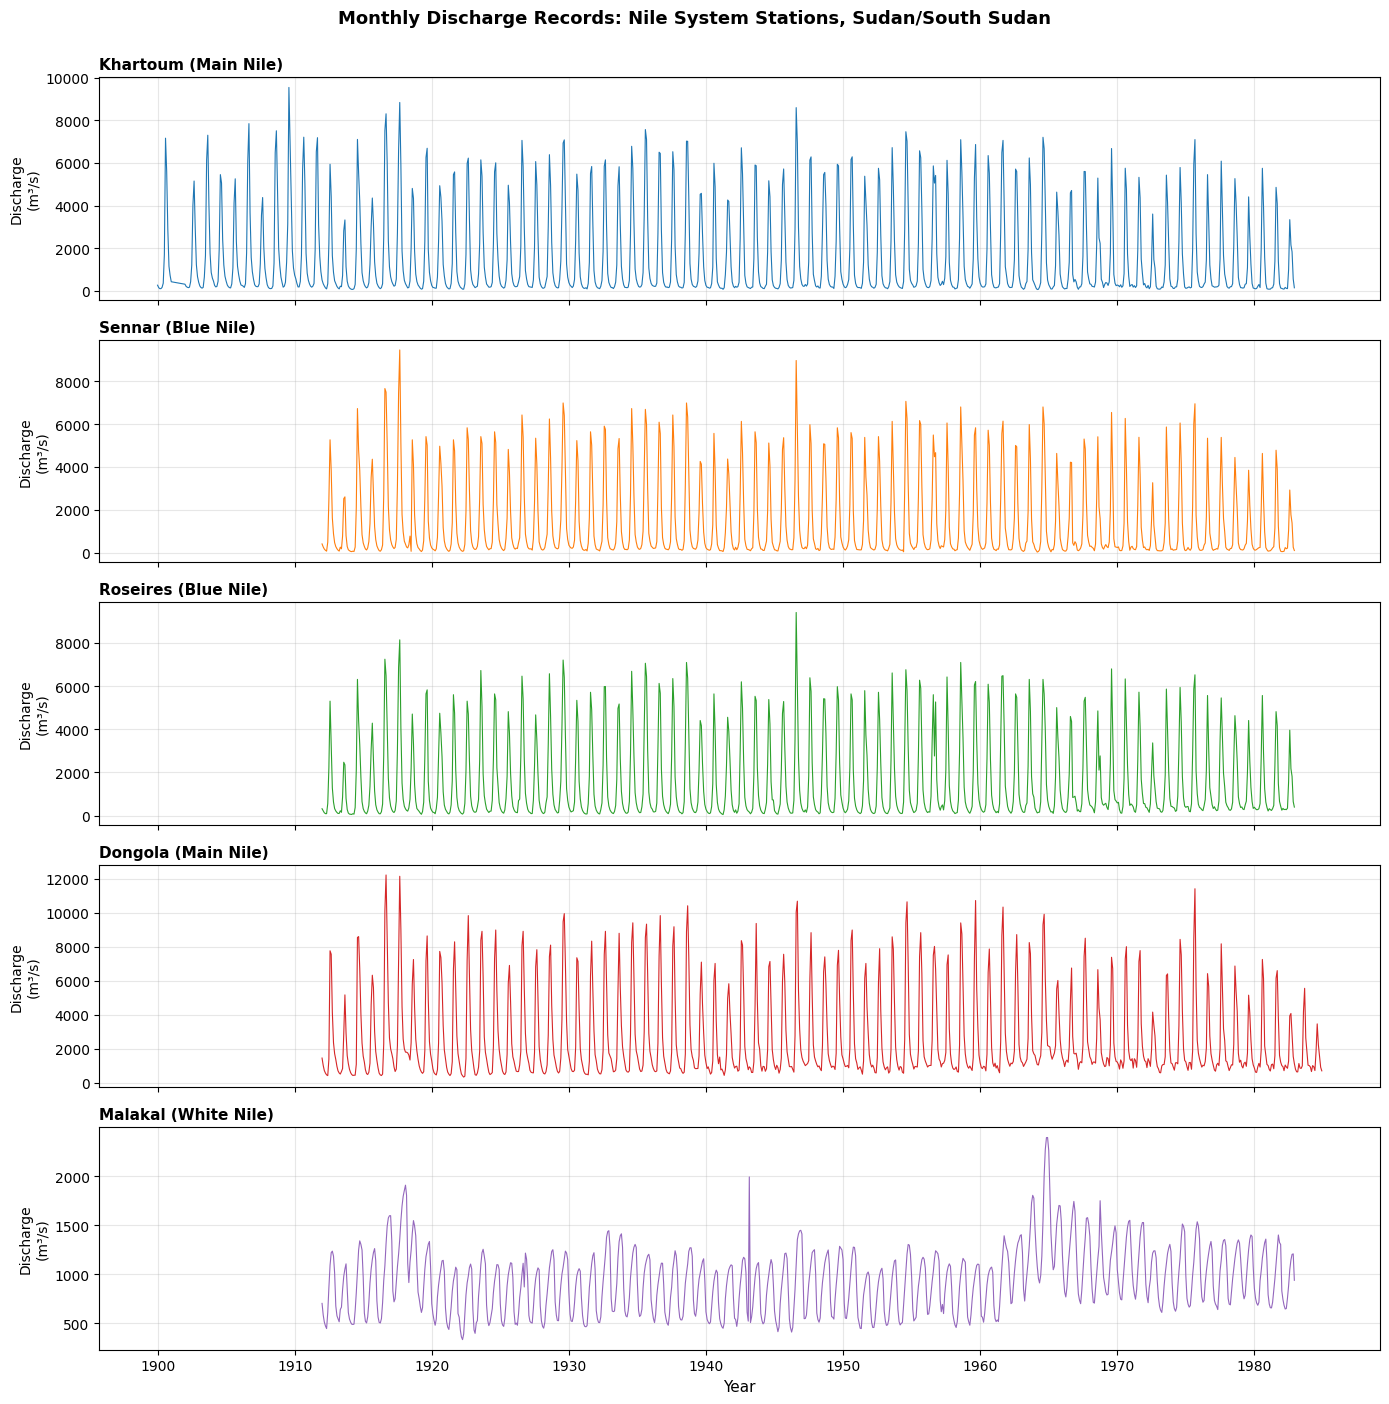

In [9]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def load_with_dates(filename):
    df = pd.read_csv(filename, sep=";", skiprows=39,
                      names=["date", "time", "original", "calculated", "flag"],
                      na_values=[-999.000, "-999.000"], encoding="latin-1")
    df["discharge_filled"] = df["original"].interpolate(method="linear")
    df["date"] = pd.to_datetime(df["date"])
    return df

stations_files = {
    "Khartoum (Main Nile)": "Khartoum.txt",
    "Sennar (Blue Nile)": "Sennar.txt",
    "Roseires (Blue Nile)": "Roseires.txt",
    "Dongola (Main Nile)": "Dongola.txt",
    "Malakal (White Nile)": "Malakal.txt"
}

fig, axes = plt.subplots(5, 1, figsize=(14, 14), sharex=True)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for ax, (label, filename), color in zip(axes, stations_files.items(), colors):
    df = load_with_dates(filename)
    ax.plot(df["date"], df["discharge_filled"], color=color, linewidth=0.8)
    ax.set_ylabel("Discharge\n(m³/s)", fontsize=10)
    ax.set_title(label, fontsize=11, loc='left', fontweight='bold')
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Year", fontsize=11)
fig.suptitle("Monthly Discharge Records: Nile System Stations, Sudan/South Sudan",
             fontsize=13, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig("figure_hydrographs.png", dpi=300, bbox_inches='tight')
plt.show()

In [10]:
# Using the energy_results list we built earlier (from wavelet_energy_analysis)
# If that variable isn't in memory anymore, re-run the energy analysis cell first

stations_order = ["Khartoum", "Sennar", "Roseires", "Dongola", "Malakal"]
labels = ["Trend (A4)", "D4", "D3", "D2", "D1 (Noise)"]
colors_stack = ['#2c7fb8', '#7fcdbb', '#c7e9b4', '#feb24c', '#f03b20']

# Build a matrix: rows = stations, columns = energy % per band
energy_matrix = []
for station in stations_order:
    result = next(r for r in energy_results if r["station"] == station)
    energy_matrix.append(result["energies"])

energy_matrix = np.array(energy_matrix)  # shape: (5 stations, 5 bands)

fig, ax = plt.subplots(figsize=(11, 6))

bottom = np.zeros(len(stations_order))
for i, (label, color) in enumerate(zip(labels, colors_stack)):
    values = energy_matrix[:, i]
    ax.bar(stations_order, values, bottom=bottom, label=label, color=color, edgecolor='white', linewidth=0.5)
    bottom += values

ax.set_ylabel("Energy Distribution (%)", fontsize=11)
ax.set_title("Wavelet Energy Distribution by Station: Trend vs Seasonal vs Noise Components",
             fontsize=12, fontweight='bold')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=5, frameon=False)
ax.set_ylim(0, 100)
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig("figure_wavelet_energy.png", dpi=300, bbox_inches='tight')
plt.show()

NameError: name 'energy_results' is not defined

In [11]:
def wavelet_energy_analysis(filename, station_name):
    df = pd.read_csv(filename, sep=";", skiprows=39,
                      names=["date", "time", "original", "calculated", "flag"],
                      na_values=[-999.000, "-999.000"], encoding="latin-1")
    df["discharge_filled"] = df["original"].interpolate(method="linear")
    signal = df["discharge_filled"].dropna().values

    coeffs = pywt.wavedec(signal, 'db4', level=4)

    energies = [np.sum(c**2) for c in coeffs]
    total_energy = sum(energies)
    energy_pct = [e/total_energy*100 for e in energies]

    cv = np.std(signal) / np.mean(signal)
    high_freq_energy = energy_pct[-1] + energy_pct[-2]

    return {"station": station_name, "cv": cv, "high_freq_energy": high_freq_energy,
            "trend_energy": energy_pct[0], "energies": energy_pct}

energy_results = []
for filename, station_name in [("Khartoum.txt", "Khartoum"), ("Sennar.txt", "Sennar"),
                                  ("Roseires.txt", "Roseires"), ("Dongola.txt", "Dongola"),
                                  ("Malakal.txt", "Malakal")]:
    energy_results.append(wavelet_energy_analysis(filename, station_name))

print("Energy results reloaded:", len(energy_results), "stations")

Energy results reloaded: 5 stations


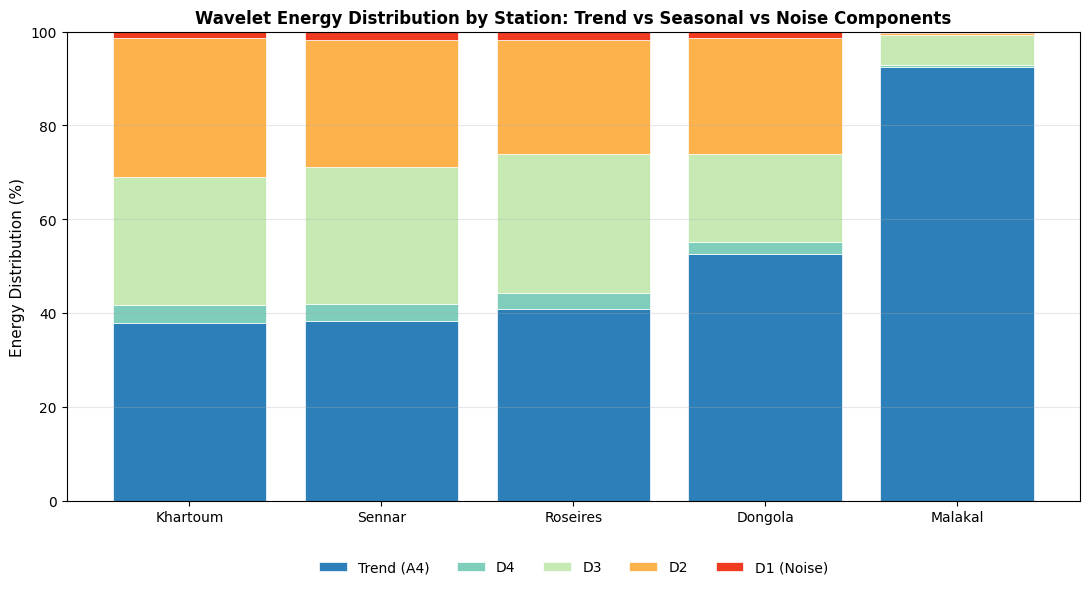

In [12]:
# Using the energy_results list we built earlier (from wavelet_energy_analysis)
# If that variable isn't in memory anymore, re-run the energy analysis cell first

stations_order = ["Khartoum", "Sennar", "Roseires", "Dongola", "Malakal"]
labels = ["Trend (A4)", "D4", "D3", "D2", "D1 (Noise)"]
colors_stack = ['#2c7fb8', '#7fcdbb', '#c7e9b4', '#feb24c', '#f03b20']

# Build a matrix: rows = stations, columns = energy % per band
energy_matrix = []
for station in stations_order:
    result = next(r for r in energy_results if r["station"] == station)
    energy_matrix.append(result["energies"])

energy_matrix = np.array(energy_matrix)  # shape: (5 stations, 5 bands)

fig, ax = plt.subplots(figsize=(11, 6))

bottom = np.zeros(len(stations_order))
for i, (label, color) in enumerate(zip(labels, colors_stack)):
    values = energy_matrix[:, i]
    ax.bar(stations_order, values, bottom=bottom, label=label, color=color, edgecolor='white', linewidth=0.5)
    bottom += values

ax.set_ylabel("Energy Distribution (%)", fontsize=11)
ax.set_title("Wavelet Energy Distribution by Station: Trend vs Seasonal vs Noise Components",
             fontsize=12, fontweight='bold')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=5, frameon=False)
ax.set_ylim(0, 100)
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig("figure_wavelet_energy.png", dpi=300, bbox_inches='tight')
plt.show()

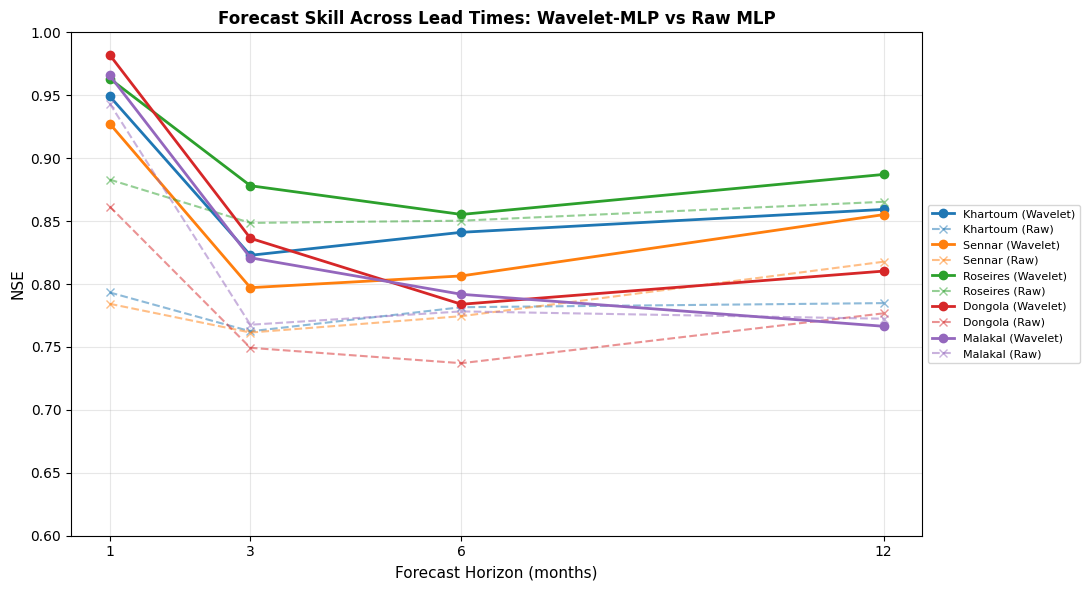

In [13]:
# Using all_horizon_results from earlier - re-run that cell first if it's gone (NameError check)

df_horizon = pd.DataFrame(all_horizon_results)

fig, ax = plt.subplots(figsize=(11, 6))

stations_order = ["Khartoum", "Sennar", "Roseires", "Dongola", "Malakal"]
colors_h = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for station, color in zip(stations_order, colors_h):
    subset = df_horizon[df_horizon["station"] == station]
    ax.plot(subset["horizon"], subset["nse_den"], marker='o', color=color,
            label=f"{station} (Wavelet)", linewidth=2)
    ax.plot(subset["horizon"], subset["nse_raw"], marker='x', color=color,
            linestyle='--', alpha=0.5, label=f"{station} (Raw)")

ax.set_xlabel("Forecast Horizon (months)", fontsize=11)
ax.set_ylabel("NSE", fontsize=11)
ax.set_title("Forecast Skill Across Lead Times: Wavelet-MLP vs Raw MLP",
             fontsize=12, fontweight='bold')
ax.set_xticks([1, 3, 6, 12])
ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=8, ncol=1)
ax.grid(True, alpha=0.3)
ax.set_ylim(0.6, 1.0)

plt.tight_layout()
plt.savefig("figure_multihorizon.png", dpi=300, bbox_inches='tight')
plt.show()

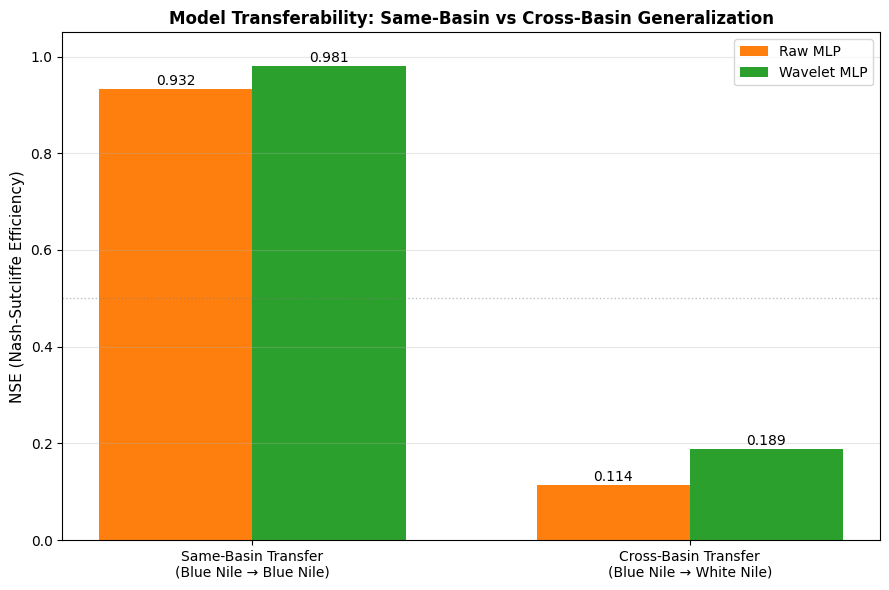

In [14]:
fig, ax = plt.subplots(figsize=(9, 6))

categories = ["Same-Basin Transfer\n(Blue Nile → Blue Nile)", "Cross-Basin Transfer\n(Blue Nile → White Nile)"]
raw_scores = [0.932, 0.114]
wavelet_scores = [0.981, 0.189]

x = np.arange(len(categories))
width = 0.35

bars1 = ax.bar(x - width/2, raw_scores, width, label='Raw MLP', color='#ff7f0e')
bars2 = ax.bar(x + width/2, wavelet_scores, width, label='Wavelet MLP', color='#2ca02c')

# Add value labels on top of bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3), textcoords="offset points", ha='center', fontsize=10)

ax.set_ylabel("NSE (Nash-Sutcliffe Efficiency)", fontsize=11)
ax.set_title("Model Transferability: Same-Basin vs Cross-Basin Generalization",
             fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=10)
ax.legend()
ax.set_ylim(0, 1.05)
ax.grid(True, axis='y', alpha=0.3)
ax.axhline(y=0.5, color='gray', linestyle=':', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.savefig("figure_transfer_learning.png", dpi=300, bbox_inches='tight')
plt.show()

In [15]:
df_block = pd.DataFrame(all_block_results)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

stations_order = ["Khartoum", "Sennar", "Roseires", "Dongola", "Malakal"]
colors_b = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for station, color in zip(stations_order, colors_b):
    subset = df_block[df_block["station"] == station]
    axes[0].plot(subset["missing_pct"], subset["nse_raw"], marker='o', color=color, label=station)
    axes[1].plot(subset["missing_pct"], subset["nse_den"], marker='o', color=color, label=station)

axes[0].set_title("Raw MLP: NSE vs Block-Gap Missing Data %", fontsize=11, fontweight='bold')
axes[1].set_title("Wavelet-Denoised MLP: NSE vs Block-Gap Missing Data %", fontsize=11, fontweight='bold')

for ax in axes:
    ax.set_xlabel("Missing Data (%)", fontsize=10)
    ax.set_ylabel("NSE", fontsize=10)
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0.6, 1.0)

fig.suptitle("Robustness to Realistic Contiguous Data Gaps (12-month blocks)",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("figure_block_gap_robustness.png", dpi=300, bbox_inches='tight')
plt.show()

NameError: name 'all_block_results' is not defined

In [16]:
def run_block_missing_test(filename, station_name, block_sizes_pct=[0.0, 0.1, 0.2, 0.3, 0.4]):
    df = pd.read_csv(filename, sep=";", skiprows=39,
                      names=["date", "time", "original", "calculated", "flag"],
                      na_values=[-999.000, "-999.000"], encoding="latin-1")
    df["discharge_filled"] = df["original"].interpolate(method="linear")
    full_signal = df["discharge_filled"].dropna().values

    results = []

    for pct in block_sizes_pct:
        np.random.seed(42)
        signal_with_gaps = full_signal.copy()
        n_total_missing = int(len(signal_with_gaps) * pct)

        if n_total_missing > 0:
            block_length = 12
            n_blocks = max(1, n_total_missing // block_length)
            for _ in range(n_blocks):
                start = np.random.randint(0, len(signal_with_gaps) - block_length)
                signal_with_gaps[start:start+block_length] = np.nan

        signal_filled = pd.Series(signal_with_gaps).interpolate(method="linear").bfill().ffill().values

        coeffs = pywt.wavedec(signal_filled, 'db4', level=4)
        threshold = np.std(coeffs[-1]) * 2
        denoised_coeffs = coeffs.copy()
        denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')
        denoised_signal = pywt.waverec(denoised_coeffs, 'db4')[:len(signal_filled)]

        X_raw, y_raw = create_lagged_features(signal_filled, n_lags=12)
        X_den, y_den = create_lagged_features(denoised_signal, n_lags=12)

        split_idx = int(len(X_raw) * 0.8)
        X_raw_train, X_raw_test = X_raw[:split_idx], X_raw[split_idx:]
        y_raw_train, y_raw_test = y_raw[:split_idx], y_raw[split_idx:]
        X_den_train, X_den_test = X_den[:split_idx], X_den[split_idx:]
        y_den_train, y_den_test = y_den[:split_idx], y_den[split_idx:]

        model_raw = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
        model_raw.fit(X_raw_train, y_raw_train)
        pred_raw = model_raw.predict(X_raw_test)

        model_den = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
        model_den.fit(X_den_train, y_den_train)
        pred_den = model_den.predict(X_den_test)

        nse_raw = nse(y_raw_test, pred_raw)
        nse_den = nse(y_den_test, pred_den)

        results.append({"station": station_name, "missing_pct": pct*100,
                        "nse_raw": nse_raw, "nse_den": nse_den})
    return results

all_block_results = []
for filename, station_name in [("Khartoum.txt", "Khartoum"), ("Sennar.txt", "Sennar"),
                                  ("Roseires.txt", "Roseires"), ("Dongola.txt", "Dongola"),
                                  ("Malakal.txt", "Malakal")]:
    all_block_results.extend(run_block_missing_test(filename, station_name))

print("Block results reloaded:", len(all_block_results), "records")

Block results reloaded: 25 records


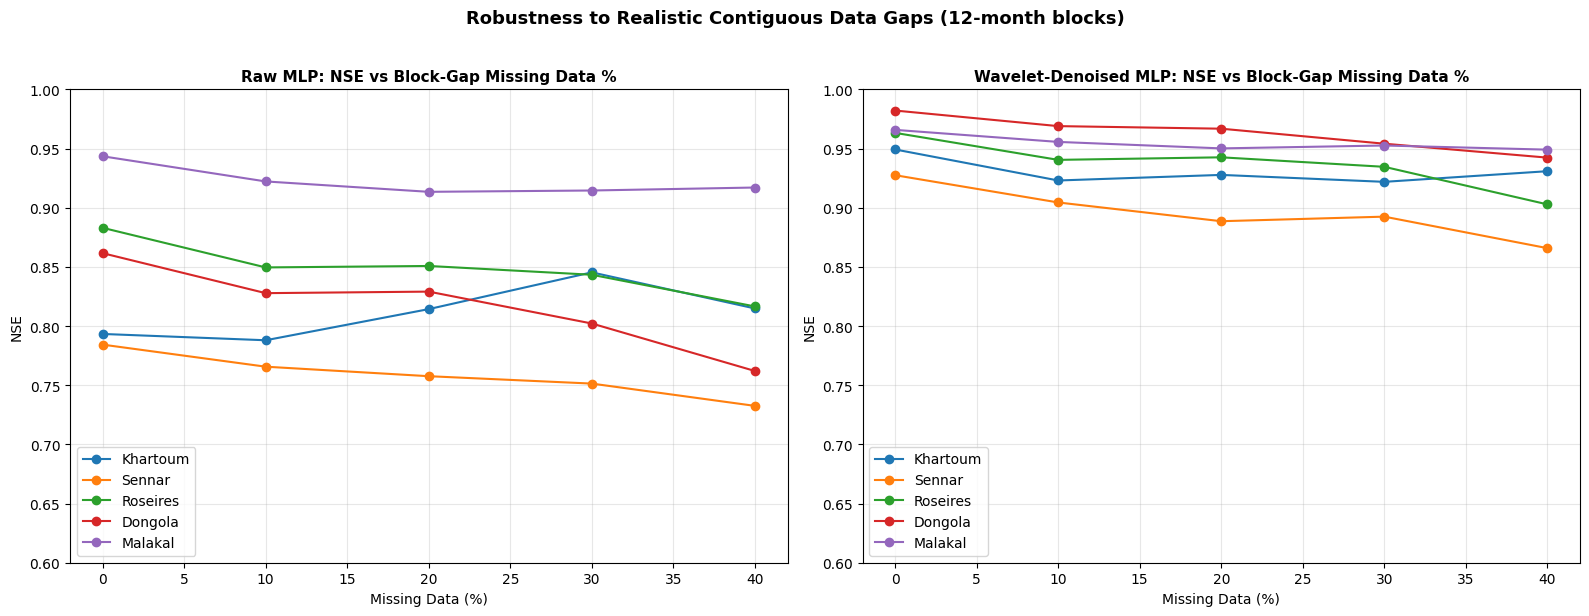

In [17]:
df_block = pd.DataFrame(all_block_results)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

stations_order = ["Khartoum", "Sennar", "Roseires", "Dongola", "Malakal"]
colors_b = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for station, color in zip(stations_order, colors_b):
    subset = df_block[df_block["station"] == station]
    axes[0].plot(subset["missing_pct"], subset["nse_raw"], marker='o', color=color, label=station)
    axes[1].plot(subset["missing_pct"], subset["nse_den"], marker='o', color=color, label=station)

axes[0].set_title("Raw MLP: NSE vs Block-Gap Missing Data %", fontsize=11, fontweight='bold')
axes[1].set_title("Wavelet-Denoised MLP: NSE vs Block-Gap Missing Data %", fontsize=11, fontweight='bold')

for ax in axes:
    ax.set_xlabel("Missing Data (%)", fontsize=10)
    ax.set_ylabel("NSE", fontsize=10)
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0.6, 1.0)

fig.suptitle("Robustness to Realistic Contiguous Data Gaps (12-month blocks)",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("figure_block_gap_robustness.png", dpi=300, bbox_inches='tight')
plt.show()

In [18]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
import os
project_path = "/content/drive/MyDrive/iwrm_paper"
os.makedirs(project_path, exist_ok=True)
os.makedirs(f"{project_path}/figures", exist_ok=True)
os.makedirs(f"{project_path}/data", exist_ok=True)
print("Folders created at:", project_path)

Folders created at: /content/drive/MyDrive/iwrm_paper


In [20]:
from google.colab import drive
drive.mount('/content/drive')

import os
project_path = "/content/drive/MyDrive/iwrm_paper"
os.makedirs(project_path, exist_ok=True)
os.makedirs(f"{project_path}/figures", exist_ok=True)
os.makedirs(f"{project_path}/data", exist_ok=True)
print("Ready:", project_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ready: /content/drive/MyDrive/iwrm_paper


In [21]:
import pandas as pd
import numpy as np
import pywt
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from scipy.stats import wilcoxon

def load_signal(filename):
    df = pd.read_csv(filename, sep=";", skiprows=39,
                      names=["date", "time", "original", "calculated", "flag"],
                      na_values=[-999.000, "-999.000"], encoding="latin-1")
    df["discharge_filled"] = df["original"].interpolate(method="linear")
    return df["discharge_filled"].dropna().values

def create_lagged_features(data, n_lags=12):
    X, y = [], []
    for i in range(n_lags, len(data)):
        X.append(data[i-n_lags:i])
        y.append(data[i])
    return np.array(X), np.array(y)

def nse(observed, predicted):
    return 1 - (np.sum((observed - predicted)**2) / np.sum((observed - np.mean(observed))**2))

def kge(observed, predicted):
    r = np.corrcoef(observed, predicted)[0, 1]
    alpha = np.std(predicted) / np.std(observed)
    beta = np.mean(predicted) / np.mean(observed)
    return 1 - np.sqrt((r-1)**2 + (alpha-1)**2 + (beta-1)**2)

print("Setup complete")

Setup complete


In [22]:
stations_files = {
    "Khartoum": "Khartoum.txt", "Sennar": "Sennar.txt", "Roseires": "Roseires.txt",
    "Dongola": "Dongola.txt", "Malakal": "Malakal.txt"
}

signals = {}
denoised_signals = {}
for name, filename in stations_files.items():
    sig = load_signal(filename)
    coeffs = pywt.wavedec(sig, 'db4', level=4)
    threshold = np.std(coeffs[-1]) * 2
    denoised_coeffs = coeffs.copy()
    denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')
    denoised_sig = pywt.waverec(denoised_coeffs, 'db4')[:len(sig)]
    signals[name] = sig
    denoised_signals[name] = denoised_sig

print("Loaded and processed:", list(signals.keys()))

Loaded and processed: ['Khartoum', 'Sennar', 'Roseires', 'Dongola', 'Malakal']


In [23]:
baseline_results = []
for name in stations_files:
    sig, den = signals[name], denoised_signals[name]
    X_raw, y_raw = create_lagged_features(sig, 12)
    X_den, y_den = create_lagged_features(den, 12)
    split = int(len(X_raw)*0.8)

    m_raw = MLPRegressor(hidden_layer_sizes=(64,32), max_iter=2000, random_state=42)
    m_raw.fit(X_raw[:split], y_raw[:split])
    pred_raw = m_raw.predict(X_raw[split:])

    m_den = MLPRegressor(hidden_layer_sizes=(64,32), max_iter=2000, random_state=42)
    m_den.fit(X_den[:split], y_den[:split])
    pred_den = m_den.predict(X_den[split:])

    pred_naive = X_raw[split:, -1]

    baseline_results.append({
        "station": name,
        "rmse_naive": np.sqrt(mean_squared_error(y_raw[split:], pred_naive)),
        "rmse_raw": np.sqrt(mean_squared_error(y_raw[split:], pred_raw)),
        "rmse_den": np.sqrt(mean_squared_error(y_den[split:], pred_den)),
        "nse_raw": nse(y_raw[split:], pred_raw),
        "nse_den": nse(y_den[split:], pred_den)
    })

df_baseline = pd.DataFrame(baseline_results)
print(df_baseline)

    station   rmse_naive    rmse_raw    rmse_den   nse_raw   nse_den
0  Khartoum  1512.248494  780.419514  378.747556  0.793304  0.949188
1    Sennar  1414.370603  742.982848  418.556433  0.784284  0.927446
2  Roseires  1359.019418  555.669728  303.307256  0.882982  0.963214
3   Dongola  1792.404264  776.096905  274.500417  0.861564  0.982080
4   Malakal   150.322788   64.043092   49.413246  0.943436  0.965746


In [24]:
energy_results = []
for name in stations_files:
    sig = signals[name]
    coeffs = pywt.wavedec(sig, 'db4', level=4)
    energies = [np.sum(c**2) for c in coeffs]
    total = sum(energies)
    energy_pct = [e/total*100 for e in energies]
    cv = np.std(sig) / np.mean(sig)
    energy_results.append({"station": name, "cv": cv, "energies": energy_pct,
                            "trend_energy": energy_pct[0], "high_freq_energy": energy_pct[-1]+energy_pct[-2]})

df_energy = pd.DataFrame(energy_results)
print(df_energy[["station", "trend_energy", "high_freq_energy", "cv"]])

    station  trend_energy  high_freq_energy        cv
0  Khartoum     37.931372         30.930072  1.330593
1    Sennar     38.311524         28.846067  1.317281
2  Roseires     41.007755         26.150972  1.228458
3   Dongola     52.625033         25.986267  0.984230
4   Malakal     92.352093          0.831129  0.353703


In [25]:
def missing_data_test(sig, missing_pct, mode="random"):
    np.random.seed(42)
    sig_gaps = sig.copy()
    n_missing = int(len(sig_gaps) * missing_pct)

    if n_missing > 0:
        if mode == "random":
            idx = np.random.choice(len(sig_gaps), n_missing, replace=False)
            sig_gaps[idx] = np.nan
        else:  # block
            block_len = 12
            n_blocks = max(1, n_missing // block_len)
            for _ in range(n_blocks):
                start = np.random.randint(0, len(sig_gaps) - block_len)
                sig_gaps[start:start+block_len] = np.nan

    sig_filled = pd.Series(sig_gaps).interpolate(method="linear").bfill().ffill().values
    coeffs = pywt.wavedec(sig_filled, 'db4', level=4)
    threshold = np.std(coeffs[-1]) * 2
    denoised_coeffs = coeffs.copy()
    denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')
    denoised_sig = pywt.waverec(denoised_coeffs, 'db4')[:len(sig_filled)]
    return sig_filled, denoised_sig

robustness_results = []
for name in stations_files:
    sig = signals[name]
    for pct in [0.0, 0.1, 0.2, 0.3, 0.4]:
        for mode in ["random", "block"]:
            sig_filled, den_sig = missing_data_test(sig, pct, mode)
            X_raw, y_raw = create_lagged_features(sig_filled, 12)
            X_den, y_den = create_lagged_features(den_sig, 12)
            split = int(len(X_raw)*0.8)

            m_raw = MLPRegressor(hidden_layer_sizes=(64,32), max_iter=2000, random_state=42)
            m_raw.fit(X_raw[:split], y_raw[:split])
            pred_raw = m_raw.predict(X_raw[split:])

            m_den = MLPRegressor(hidden_layer_sizes=(64,32), max_iter=2000, random_state=42)
            m_den.fit(X_den[:split], y_den[:split])
            pred_den = m_den.predict(X_den[split:])

            robustness_results.append({
                "station": name, "missing_pct": pct*100, "mode": mode,
                "nse_raw": nse(y_raw[split:], pred_raw), "nse_den": nse(y_den[split:], pred_den)
            })

df_robustness = pd.DataFrame(robustness_results)
print(df_robustness.head(10))
print(f"\nTotal rows: {len(df_robustness)}")

    station  missing_pct    mode   nse_raw   nse_den
0  Khartoum          0.0  random  0.793304  0.949188
1  Khartoum          0.0   block  0.793304  0.949188
2  Khartoum         10.0  random  0.790543  0.968668
3  Khartoum         10.0   block  0.787976  0.922980
4  Khartoum         20.0  random  0.781264  0.971094
5  Khartoum         20.0   block  0.814297  0.927697
6  Khartoum         30.0  random  0.652919  0.954619
7  Khartoum         30.0   block  0.845356  0.921836
8  Khartoum         40.0  random  0.606785  0.942706
9  Khartoum         40.0   block  0.814836  0.930823

Total rows: 50


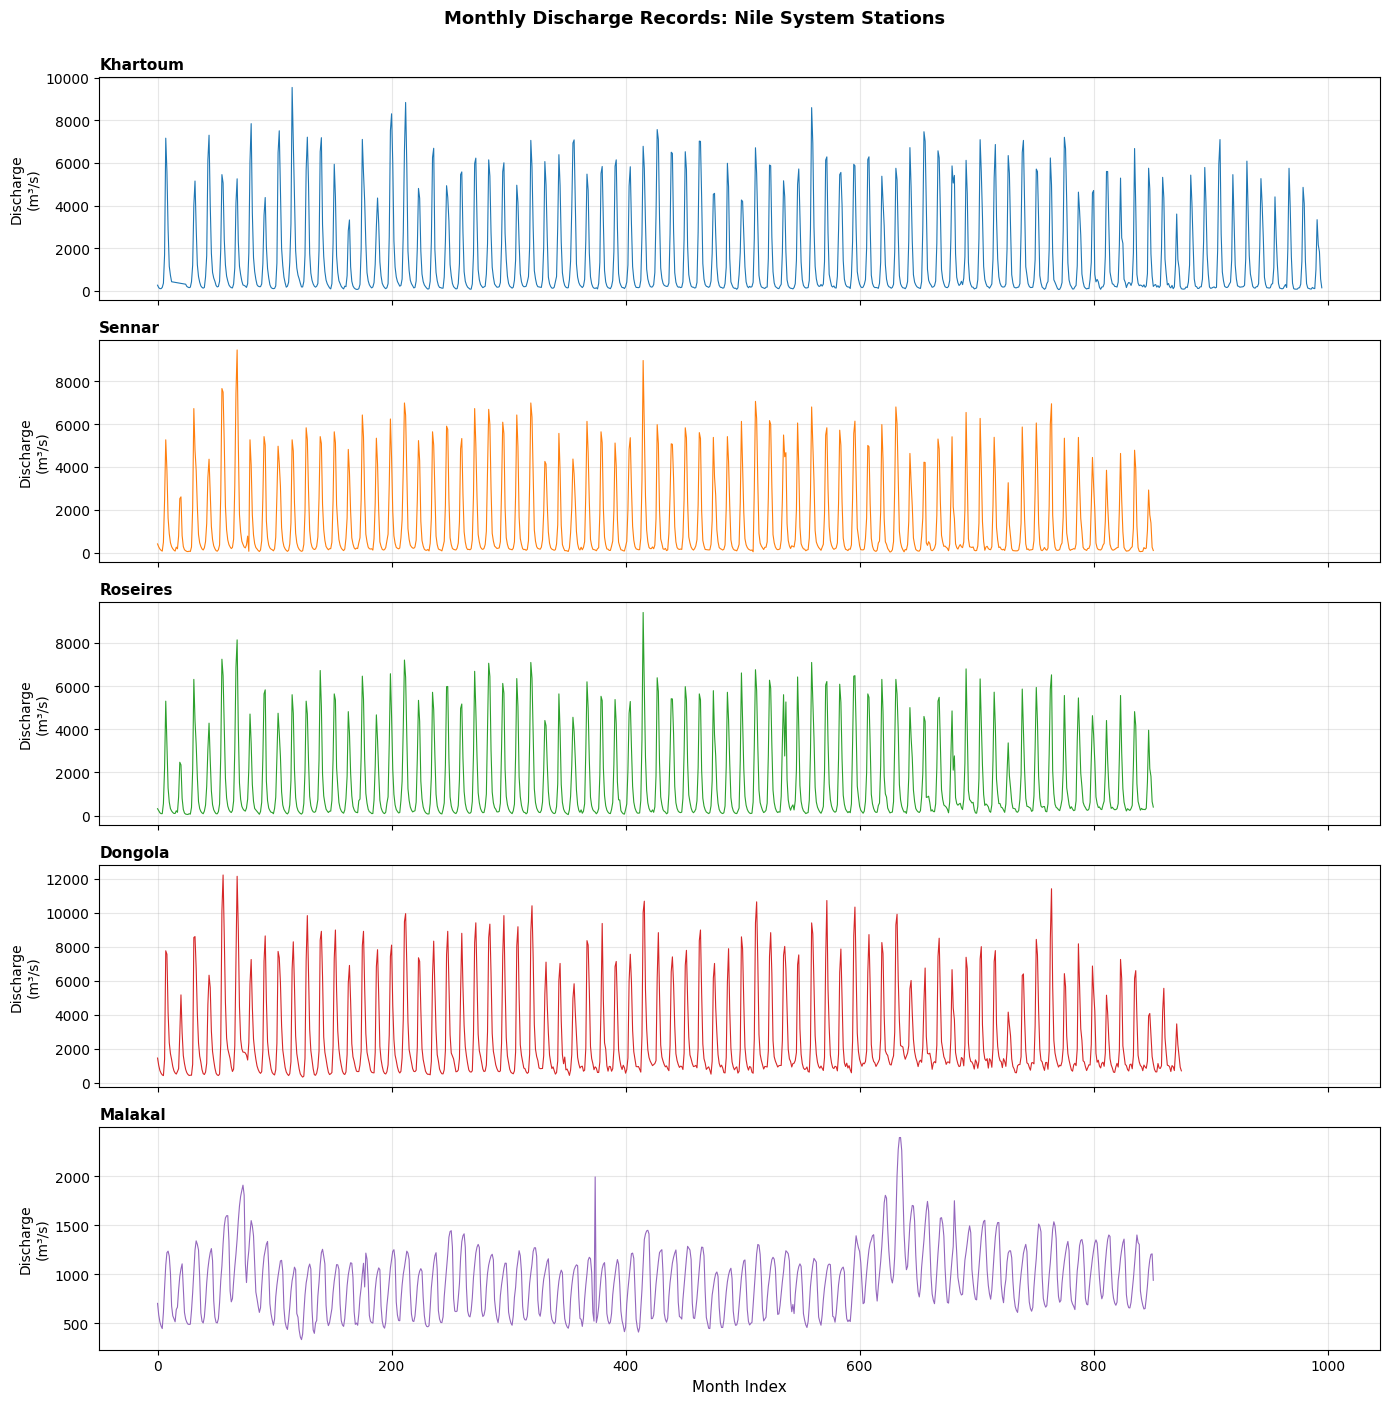

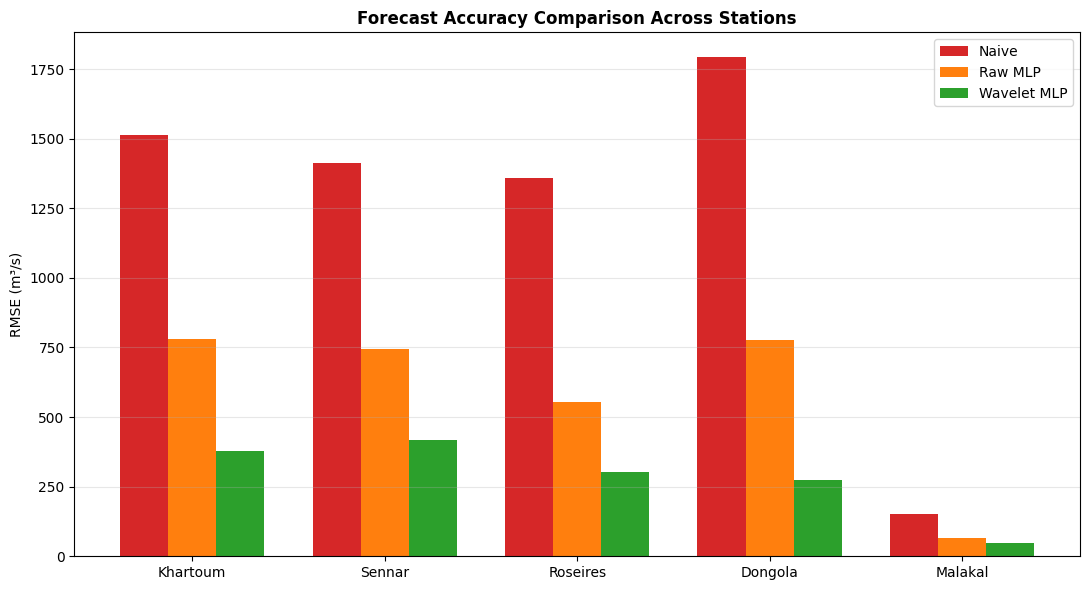

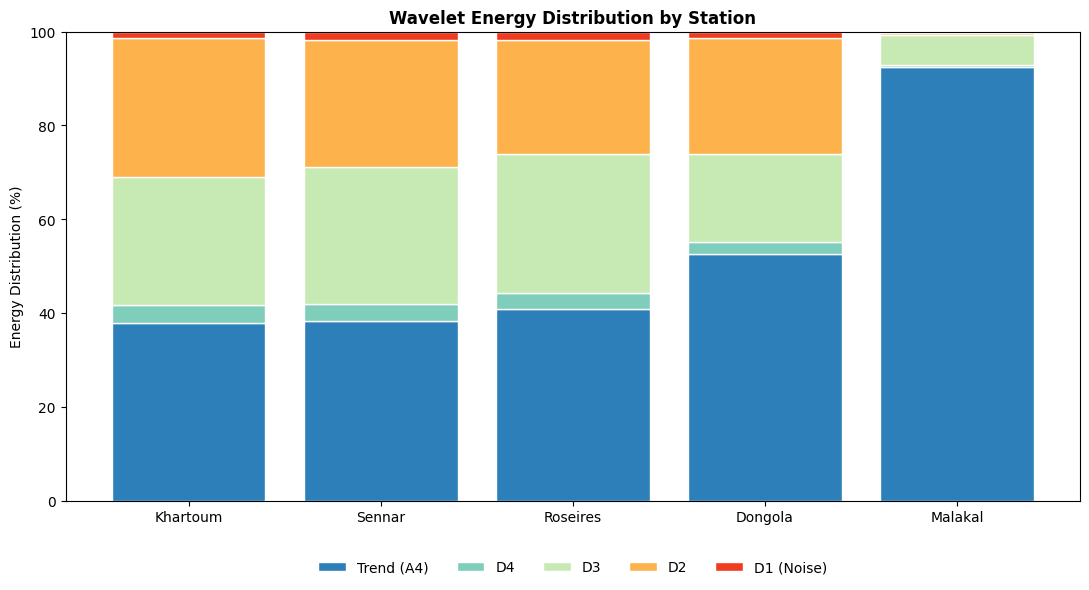

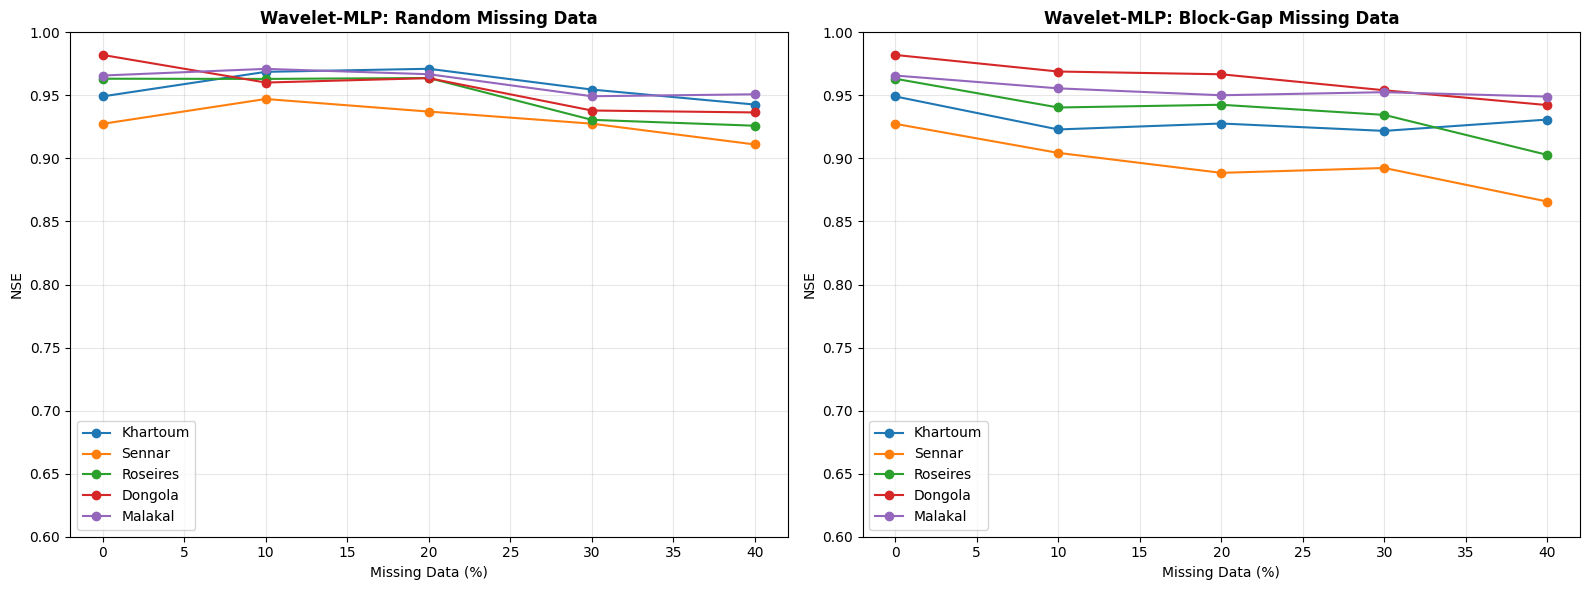

All figures saved to: /content/drive/MyDrive/iwrm_paper/figures/


In [26]:
project_path = "/content/drive/MyDrive/iwrm_paper"

# Figure 1: Hydrograph overview
fig, axes = plt.subplots(5, 1, figsize=(14, 14), sharex=True)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for ax, name, color in zip(axes, stations_files.keys(), colors):
    ax.plot(signals[name], color=color, linewidth=0.8)
    ax.set_ylabel("Discharge\n(m³/s)", fontsize=10)
    ax.set_title(name, fontsize=11, loc='left', fontweight='bold')
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Month Index", fontsize=11)
fig.suptitle("Monthly Discharge Records: Nile System Stations", fontsize=13, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig(f"{project_path}/figures/fig1_hydrographs.png", dpi=300, bbox_inches='tight')
plt.show()

# Figure 2: Baseline comparison bar chart
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(df_baseline))
width = 0.25
ax.bar(x - width, df_baseline["rmse_naive"], width, label='Naive', color='#d62728')
ax.bar(x, df_baseline["rmse_raw"], width, label='Raw MLP', color='#ff7f0e')
ax.bar(x + width, df_baseline["rmse_den"], width, label='Wavelet MLP', color='#2ca02c')
ax.set_xticks(x)
ax.set_xticklabels(df_baseline["station"])
ax.set_ylabel("RMSE (m³/s)")
ax.set_title("Forecast Accuracy Comparison Across Stations", fontweight='bold')
ax.legend()
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f"{project_path}/figures/fig2_baseline_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

# Figure 3: Wavelet energy distribution
labels = ["Trend (A4)", "D4", "D3", "D2", "D1 (Noise)"]
colors_stack = ['#2c7fb8', '#7fcdbb', '#c7e9b4', '#feb24c', '#f03b20']
energy_matrix = np.array([r["energies"] for r in energy_results])
fig, ax = plt.subplots(figsize=(11, 6))
bottom = np.zeros(len(stations_files))
for i, (label, color) in enumerate(zip(labels, colors_stack)):
    ax.bar(list(stations_files.keys()), energy_matrix[:, i], bottom=bottom, label=label, color=color, edgecolor='white')
    bottom += energy_matrix[:, i]
ax.set_ylabel("Energy Distribution (%)")
ax.set_title("Wavelet Energy Distribution by Station", fontweight='bold')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=5, frameon=False)
ax.set_ylim(0, 100)
plt.tight_layout()
plt.savefig(f"{project_path}/figures/fig3_wavelet_energy.png", dpi=300, bbox_inches='tight')
plt.show()

# Figure 4: Robustness curves (random vs block, side by side)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for name, color in zip(stations_files.keys(), colors):
    for i, mode in enumerate(["random", "block"]):
        subset = df_robustness[(df_robustness["station"]==name) & (df_robustness["mode"]==mode)]
        axes[i].plot(subset["missing_pct"], subset["nse_den"], marker='o', color=color, label=name)
axes[0].set_title("Wavelet-MLP: Random Missing Data", fontweight='bold')
axes[1].set_title("Wavelet-MLP: Block-Gap Missing Data", fontweight='bold')
for ax in axes:
    ax.set_xlabel("Missing Data (%)")
    ax.set_ylabel("NSE")
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0.6, 1.0)
plt.tight_layout()
plt.savefig(f"{project_path}/figures/fig4_robustness.png", dpi=300, bbox_inches='tight')
plt.show()

print("All figures saved to:", f"{project_path}/figures/")

In [27]:
horizon_results = []
for name in stations_files:
    sig, den = signals[name], denoised_signals[name]
    for horizon in [1, 3, 6, 12]:
        n_lags = 12
        X_raw, y_raw, X_den, y_den = [], [], [], []
        for i in range(n_lags, len(sig) - horizon + 1):
            X_raw.append(sig[i-n_lags:i]); y_raw.append(sig[i+horizon-1])
            X_den.append(den[i-n_lags:i]); y_den.append(den[i+horizon-1])
        X_raw, y_raw, X_den, y_den = np.array(X_raw), np.array(y_raw), np.array(X_den), np.array(y_den)
        split = int(len(X_raw)*0.8)

        m_raw = MLPRegressor(hidden_layer_sizes=(64,32), max_iter=2000, random_state=42)
        m_raw.fit(X_raw[:split], y_raw[:split])
        pred_raw = m_raw.predict(X_raw[split:])

        m_den = MLPRegressor(hidden_layer_sizes=(64,32), max_iter=2000, random_state=42)
        m_den.fit(X_den[:split], y_den[:split])
        pred_den = m_den.predict(X_den[split:])

        horizon_results.append({"station": name, "horizon": horizon,
                                  "nse_raw": nse(y_raw[split:], pred_raw), "nse_den": nse(y_den[split:], pred_den)})

df_horizon = pd.DataFrame(horizon_results)
print(f"Horizon results: {len(df_horizon)} rows")

Horizon results: 20 rows


In [28]:
def normalize(sig): return sig / np.mean(sig)

def process_for_transfer(filename):
    sig = load_signal(filename)
    sig_norm = normalize(sig)
    coeffs = pywt.wavedec(sig_norm, 'db4', level=4)
    threshold = np.std(coeffs[-1]) * 2
    denoised_coeffs = coeffs.copy()
    denoised_coeffs[-1] = pywt.threshold(coeffs[-1], threshold, mode='soft')
    den_sig = pywt.waverec(denoised_coeffs, 'db4')[:len(sig_norm)]
    return sig_norm, den_sig

# Same-basin: train Sennar+Roseires+Dongola, test Khartoum
train_raw, train_y_raw, train_den, train_y_den = [], [], [], []
for f in ["Sennar.txt", "Roseires.txt", "Dongola.txt"]:
    s, d = process_for_transfer(f)
    Xr, yr = create_lagged_features(s, 12); Xd, yd = create_lagged_features(d, 12)
    train_raw.append(Xr); train_y_raw.append(yr); train_den.append(Xd); train_y_den.append(yd)
train_raw, train_y_raw = np.vstack(train_raw), np.concatenate(train_y_raw)
train_den, train_y_den = np.vstack(train_den), np.concatenate(train_y_den)

test_s, test_d = process_for_transfer("Khartoum.txt")
Xtr, ytr = create_lagged_features(test_s, 12); Xtd, ytd = create_lagged_features(test_d, 12)

m1 = MLPRegressor(hidden_layer_sizes=(64,32), max_iter=2000, random_state=42).fit(train_raw, train_y_raw)
m2 = MLPRegressor(hidden_layer_sizes=(64,32), max_iter=2000, random_state=42).fit(train_den, train_y_den)
same_basin_raw = nse(ytr, m1.predict(Xtr))
same_basin_den = nse(ytd, m2.predict(Xtd))

# Cross-basin: train Sennar+Roseires, test Malakal
train_raw2, train_y_raw2, train_den2, train_y_den2 = [], [], [], []
for f in ["Sennar.txt", "Roseires.txt"]:
    s, d = process_for_transfer(f)
    Xr, yr = create_lagged_features(s, 12); Xd, yd = create_lagged_features(d, 12)
    train_raw2.append(Xr); train_y_raw2.append(yr); train_den2.append(Xd); train_y_den2.append(yd)
train_raw2, train_y_raw2 = np.vstack(train_raw2), np.concatenate(train_y_raw2)
train_den2, train_y_den2 = np.vstack(train_den2), np.concatenate(train_y_den2)

test_s2, test_d2 = process_for_transfer("Malakal.txt")
Xtr2, ytr2 = create_lagged_features(test_s2, 12); Xtd2, ytd2 = create_lagged_features(test_d2, 12)

m3 = MLPRegressor(hidden_layer_sizes=(64,32), max_iter=2000, random_state=42).fit(train_raw2, train_y_raw2)
m4 = MLPRegressor(hidden_layer_sizes=(64,32), max_iter=2000, random_state=42).fit(train_den2, train_y_den2)
cross_basin_raw = nse(ytr2, m3.predict(Xtr2))
cross_basin_den = nse(ytd2, m4.predict(Xtd2))

print(f"Same-basin:  Raw={same_basin_raw:.3f}  Wavelet={same_basin_den:.3f}")
print(f"Cross-basin: Raw={cross_basin_raw:.3f}  Wavelet={cross_basin_den:.3f}")

Same-basin:  Raw=0.932  Wavelet=0.981
Cross-basin: Raw=0.114  Wavelet=0.189


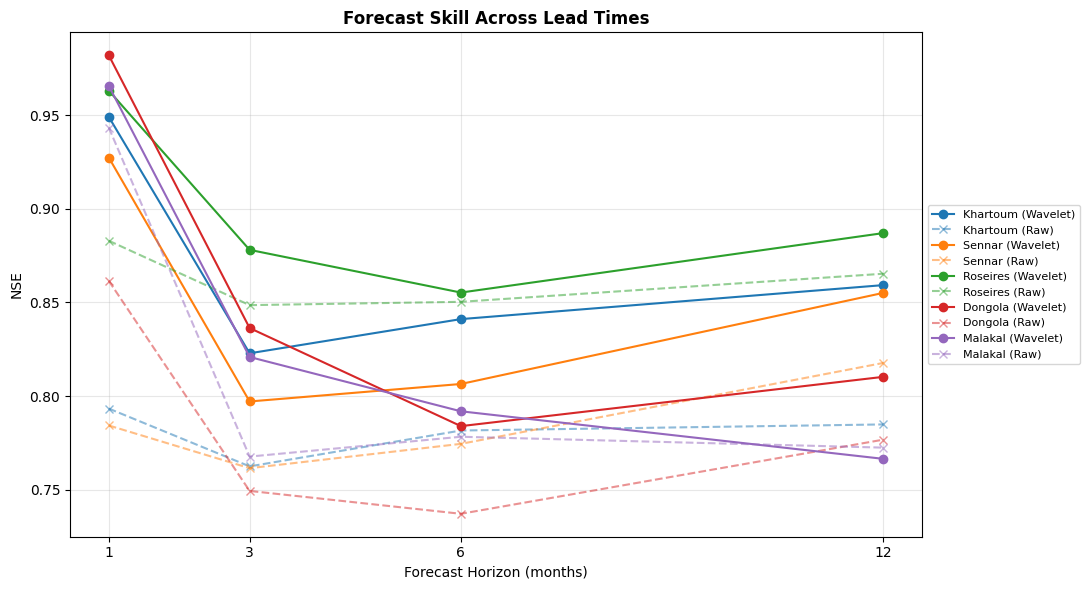

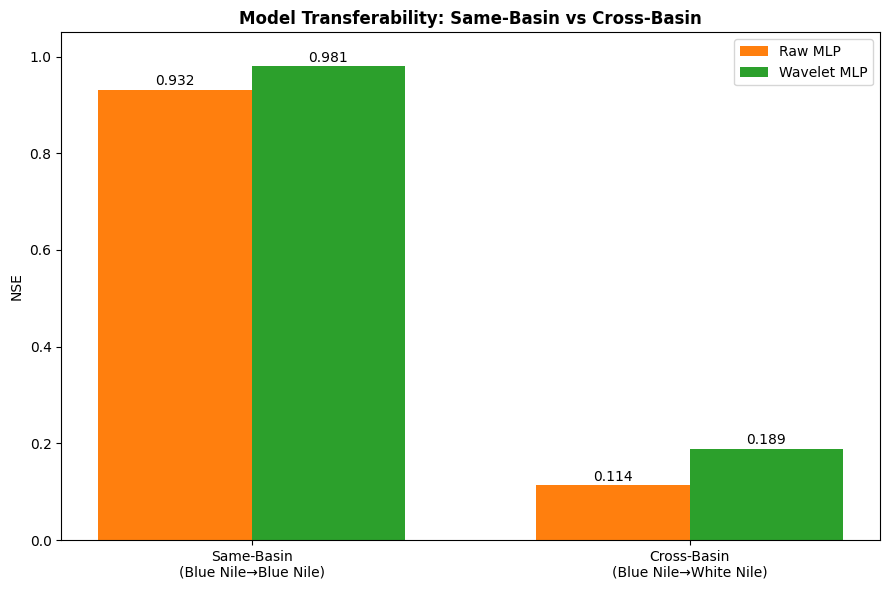

All 6 figures now saved to Drive


In [29]:
project_path = "/content/drive/MyDrive/iwrm_paper"

# Figure 5: Multi-horizon chart
fig, ax = plt.subplots(figsize=(11, 6))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for name, color in zip(stations_files.keys(), colors):
    subset = df_horizon[df_horizon["station"]==name]
    ax.plot(subset["horizon"], subset["nse_den"], marker='o', color=color, label=f"{name} (Wavelet)")
    ax.plot(subset["horizon"], subset["nse_raw"], marker='x', color=color, linestyle='--', alpha=0.5, label=f"{name} (Raw)")
ax.set_xlabel("Forecast Horizon (months)")
ax.set_ylabel("NSE")
ax.set_title("Forecast Skill Across Lead Times", fontweight='bold')
ax.set_xticks([1,3,6,12])
ax.legend(bbox_to_anchor=(1.0, 0.5), loc='center left', fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{project_path}/figures/fig5_multihorizon.png", dpi=300, bbox_inches='tight')
plt.show()

# Figure 6: Transfer learning
fig, ax = plt.subplots(figsize=(9, 6))
categories = ["Same-Basin\n(Blue Nile→Blue Nile)", "Cross-Basin\n(Blue Nile→White Nile)"]
raw_scores = [same_basin_raw, cross_basin_raw]
wav_scores = [same_basin_den, cross_basin_den]
x = np.arange(len(categories)); width = 0.35
b1 = ax.bar(x-width/2, raw_scores, width, label='Raw MLP', color='#ff7f0e')
b2 = ax.bar(x+width/2, wav_scores, width, label='Wavelet MLP', color='#2ca02c')
for bars in [b1,b2]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.3f}', xy=(bar.get_x()+bar.get_width()/2, h), xytext=(0,3), textcoords="offset points", ha='center')
ax.set_ylabel("NSE")
ax.set_title("Model Transferability: Same-Basin vs Cross-Basin", fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(categories)
ax.legend()
ax.set_ylim(0,1.05)
plt.tight_layout()
plt.savefig(f"{project_path}/figures/fig6_transfer.png", dpi=300, bbox_inches='tight')
plt.show()

print("All 6 figures now saved to Drive")

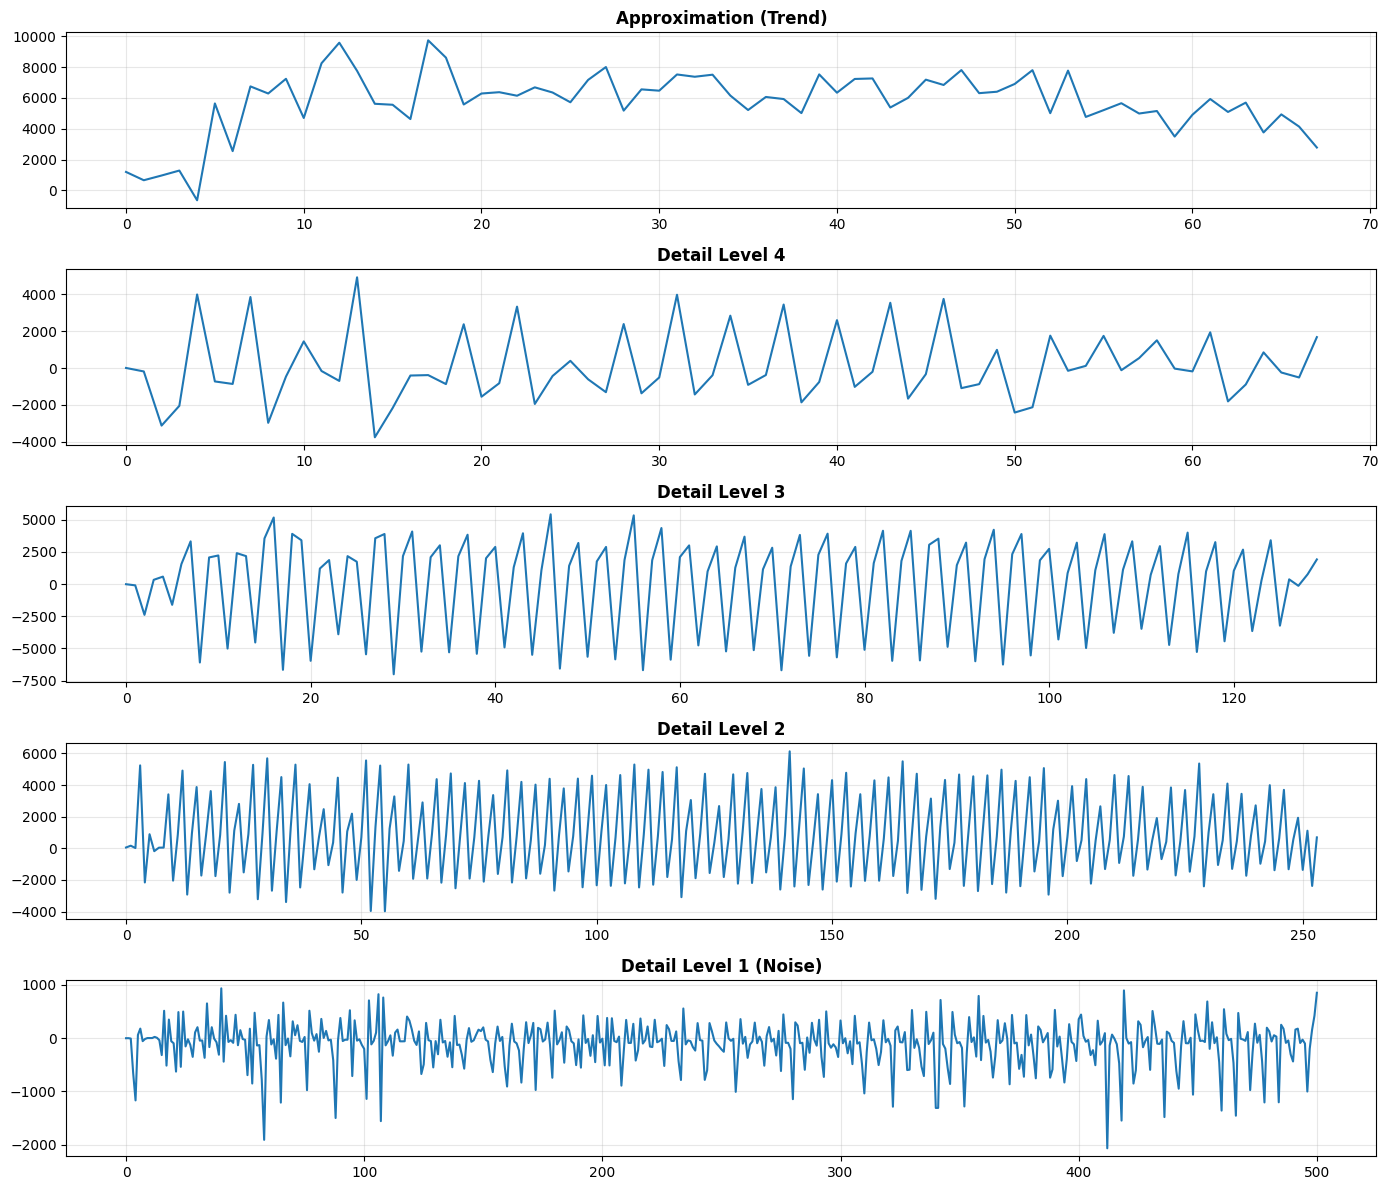

7th figure saved


In [30]:
project_path = "/content/drive/MyDrive/iwrm_paper"

sig = signals["Khartoum"]
coeffs = pywt.wavedec(sig, 'db4', level=4)
labels = ["Approximation (Trend)", "Detail Level 4", "Detail Level 3", "Detail Level 2", "Detail Level 1 (Noise)"]

fig, axes = plt.subplots(len(coeffs), 1, figsize=(14, 12))
for ax, c, label in zip(axes, coeffs, labels):
    ax.plot(c)
    ax.set_title(label, fontweight='bold')
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{project_path}/figures/fig0_wavelet_decomposition_example.png", dpi=300, bbox_inches='tight')
plt.show()

print("7th figure saved")

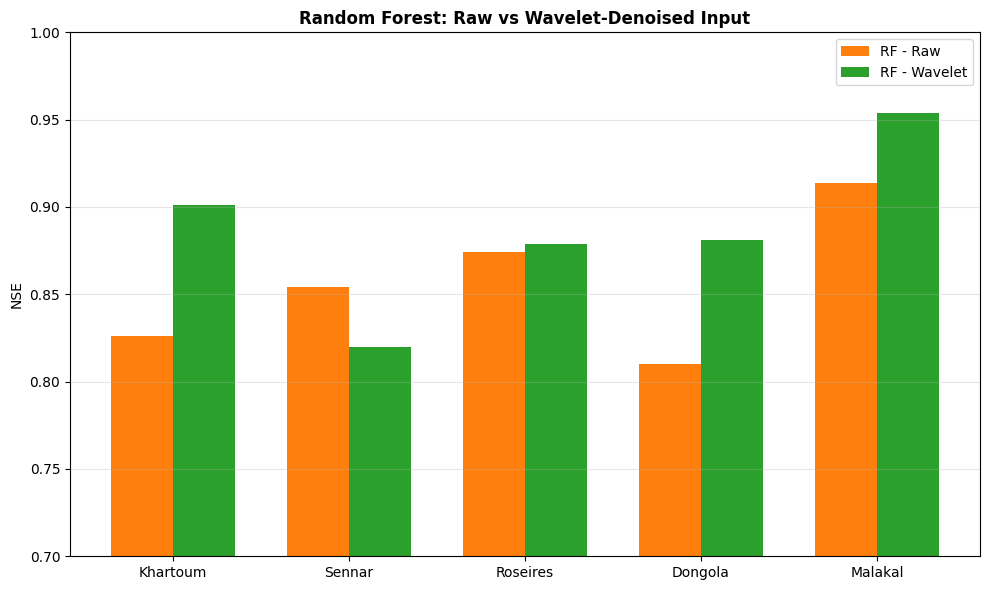

Figure 7 saved


In [31]:
project_path = "/content/drive/MyDrive/iwrm_paper"

rf_data = {
    "Khartoum": {"raw": 0.826, "wav": 0.901},
    "Sennar": {"raw": 0.854, "wav": 0.820},
    "Roseires": {"raw": 0.874, "wav": 0.879},
    "Dongola": {"raw": 0.810, "wav": 0.881},
    "Malakal": {"raw": 0.914, "wav": 0.954}
}

fig, ax = plt.subplots(figsize=(10, 6))
stations = list(rf_data.keys())
raw_vals = [rf_data[s]["raw"] for s in stations]
wav_vals = [rf_data[s]["wav"] for s in stations]
x = np.arange(len(stations)); width = 0.35
ax.bar(x-width/2, raw_vals, width, label='RF - Raw', color='#ff7f0e')
ax.bar(x+width/2, wav_vals, width, label='RF - Wavelet', color='#2ca02c')
ax.set_xticks(x); ax.set_xticklabels(stations)
ax.set_ylabel("NSE")
ax.set_title("Random Forest: Raw vs Wavelet-Denoised Input", fontweight='bold')
ax.legend()
ax.set_ylim(0.7, 1.0)
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f"{project_path}/figures/fig7_random_forest.png", dpi=300, bbox_inches='tight')
plt.show()
print("Figure 7 saved")

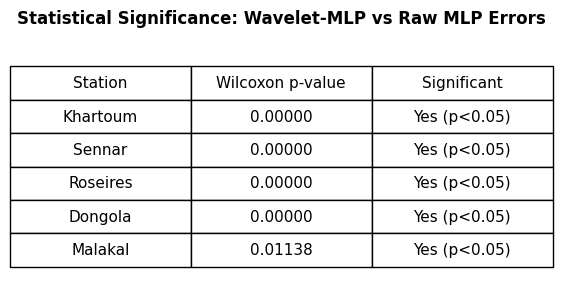

Figure 8 saved


In [32]:
sig_data = {
    "Khartoum": 0.00000, "Sennar": 0.00000, "Roseires": 0.00000,
    "Dongola": 0.00000, "Malakal": 0.01138
}

fig, ax = plt.subplots(figsize=(7, 3))
ax.axis('off')
table_data = [[s, f"{p:.5f}", "Yes (p<0.05)"] for s, p in sig_data.items()]
table = ax.table(cellText=table_data, colLabels=["Station", "Wilcoxon p-value", "Significant"],
                  cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2)
ax.set_title("Statistical Significance: Wavelet-MLP vs Raw MLP Errors", fontweight='bold', pad=20)
plt.savefig(f"{project_path}/figures/fig8_significance_table.png", dpi=300, bbox_inches='tight')
plt.show()
print("Figure 8 saved")

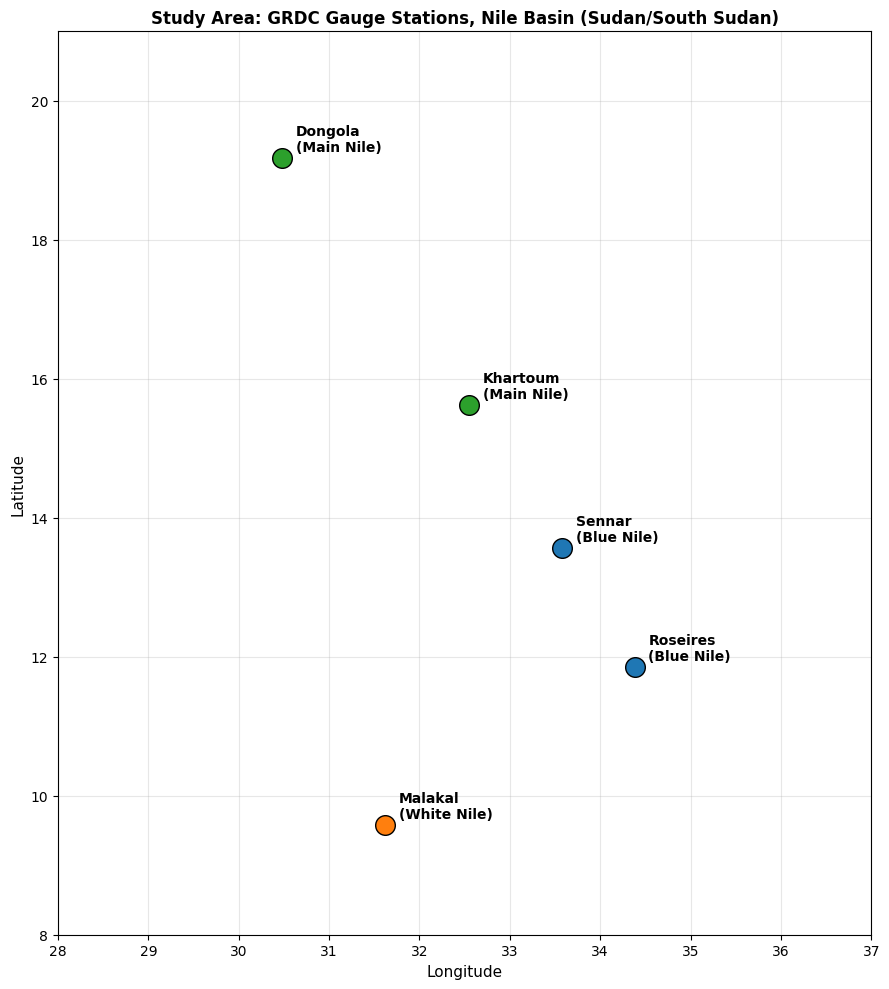

Figure 9 saved


In [33]:
fig, ax = plt.subplots(figsize=(9, 10))
station_coords = {
    "Roseires": (34.38, 11.85), "Sennar": (33.58, 13.57),
    "Khartoum": (32.55, 15.62), "Dongola": (30.48, 19.18),
    "Malakal": (31.62, 9.58)
}
river_labels = {"Roseires": "Blue Nile", "Sennar": "Blue Nile", "Khartoum": "Main Nile",
                 "Dongola": "Main Nile", "Malakal": "White Nile"}
colors_map = {"Blue Nile": "#1f77b4", "Main Nile": "#2ca02c", "White Nile": "#ff7f0e"}

for name, (lon, lat) in station_coords.items():
    ax.scatter(lon, lat, s=200, color=colors_map[river_labels[name]], edgecolor='black', zorder=3)
    ax.annotate(f"{name}\n({river_labels[name]})", (lon, lat), textcoords="offset points",
                xytext=(10, 5), fontsize=10, fontweight='bold')

ax.set_xlabel("Longitude", fontsize=11)
ax.set_ylabel("Latitude", fontsize=11)
ax.set_title("Study Area: GRDC Gauge Stations, Nile Basin (Sudan/South Sudan)", fontweight='bold')
ax.grid(True, alpha=0.3)
ax.set_xlim(28, 37)
ax.set_ylim(8, 21)
plt.tight_layout()
plt.savefig(f"{project_path}/figures/fig9_study_area_map.png", dpi=300, bbox_inches='tight')
plt.show()
print("Figure 9 saved")

In [34]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [35]:
!git config --global user.email "itshams7@users.noreply.github.com"
!git config --global user.name "itshams7"

In [36]:
!git clone https://github.com/itshams7/wavelet-streamflow-nile.git /content/repo

Cloning into '/content/repo'...


In [37]:
import os
for folder in ['notebooks', 'figures', 'data', 'results']:
    os.makedirs(f'/content/repo/{folder}', exist_ok=True)

# copy figures and data from your Drive project folder
!cp -r /content/drive/MyDrive/iwrm_paper/figures/* /content/repo/figures/
!cp -r /content/drive/MyDrive/iwrm_paper/data/* /content/repo/data/

# copy your notebook(s) — adjust filename(s) to match what's actually in your Drive folder
!cp /content/drive/MyDrive/iwrm_paper/*.ipynb /content/repo/notebooks/

cp: cannot stat '/content/drive/MyDrive/iwrm_paper/data/*': No such file or directory
cp: cannot stat '/content/drive/MyDrive/iwrm_paper/*.ipynb': No such file or directory


In [38]:
!find /content/drive/MyDrive/iwrm_paper -maxdepth 2

/content/drive/MyDrive/iwrm_paper
/content/drive/MyDrive/iwrm_paper/figures
/content/drive/MyDrive/iwrm_paper/figures/fig1_hydrographs.png
/content/drive/MyDrive/iwrm_paper/figures/fig2_baseline_comparison.png
/content/drive/MyDrive/iwrm_paper/figures/fig3_wavelet_energy.png
/content/drive/MyDrive/iwrm_paper/figures/fig4_robustness.png
/content/drive/MyDrive/iwrm_paper/figures/fig5_multihorizon.png
/content/drive/MyDrive/iwrm_paper/figures/fig6_transfer.png
/content/drive/MyDrive/iwrm_paper/figures/fig0_wavelet_decomposition_example.png
/content/drive/MyDrive/iwrm_paper/figures/fig7_random_forest.png
/content/drive/MyDrive/iwrm_paper/figures/fig8_significance_table.png
/content/drive/MyDrive/iwrm_paper/figures/fig9_study_area_map.png
/content/drive/MyDrive/iwrm_paper/data
